In [1]:
import os
import os, sys
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Sequential
import torch.optim as optim
import voxelmorph as vxm
import neurite as ne
import scipy.ndimage

os.environ['VXM_BACKEND'] = 'pytorch'

backend:pytorch
Pytorch


In [2]:
os.environ.get('VXM_BACKEND')

'pytorch'

In [3]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [4]:
# configure unet input shape (concatenation of moving and fixed images)
ndim = 3
unet_input_features = 2
# inshape = (*x_train.shape[1:], unet_input_features)

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16]
]

In [6]:
model2 = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
)

print(model2.transformer.grid.shape)

[64, 128, 128]
torch.Size([1, 3, 64, 128, 128])


In [7]:
model = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
)

model.to(device)

optimizer = optim.Adam(model.parameters(), lr=1e-4)

model.load_state_dict(
    torch.load(
        r"D:\Saito\model_analysis_pipeline_128_256_256.pth",
        map_location=device
    )
)

transformer = vxm.layers.SpatialTransformer(
    (64, 128, 128)
).to(device)

transformer256 = vxm.layers.SpatialTransformer(
    (128, 256, 256)
).to(device)

[64, 128, 128]


In [8]:
import math
import torch

band_names = ['LLL', 'LLH', 'LHL', 'LHH', 'HLL', 'HLH', 'HHL', 'HHH']

class Haar3DAnalysisOnly(nn.Module):
    def __init__(self):
        super().__init__()

        hL = torch.tensor([1.0, 1.0], dtype=torch.float32) / math.sqrt(2.0)
        hH = torch.tensor([1.0, -1.0], dtype=torch.float32) / math.sqrt(2.0)

        filters = []
        names = []

        for z_name, z_filter in zip(['L', 'H'], [hL, hH]):
            for y_name, y_filter in zip(['L', 'H'], [hL, hH]):
                for x_name, x_filter in zip(['L', 'H'], [hL, hH]):
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)
                    names.append(z_name + y_name + x_name)

        weight = torch.stack(filters, dim=0).unsqueeze(1)
        self.register_buffer('weight', weight)
        self.names = names

    def forward(self, x):
        x = F.pad(x, (0, 1, 0, 1, 0, 1))
        return F.conv3d(x, self.weight, stride=1, padding=0)

def analysis_filter_3d(x, analysis_layer):
    return analysis_layer(x)

def down_sampling_3d(w):
    return w[:, :, ::2, ::2, ::2]

def up_sampling_3d(w_down):
    B, C, D, H, W = w_down.shape
    w_up = torch.zeros(B, C, D * 2, H * 2, W * 2, dtype=w_down.dtype, device=w_down.device)
    w_up[:, :, ::2, ::2, ::2] = w_down
    return w_up

def make_3d_filter(fz, fy, fx):
    return fz[:, None, None] * fy[None, :, None] * fx[None, None, :]

def create_synthesis_filters(device):
    low = torch.tensor([1.0, 1.0], dtype=torch.float32, device=device) / math.sqrt(2.0)
    high = torch.tensor([1.0, -1.0], dtype=torch.float32, device=device) / math.sqrt(2.0)

    filters = torch.stack([
        make_3d_filter(low, low, low),
        make_3d_filter(low, low, high),
        make_3d_filter(low, high, low),
        make_3d_filter(low, high, high),
        make_3d_filter(high, low, low),
        make_3d_filter(high, low, high),
        make_3d_filter(high, high, low),
        make_3d_filter(high, high, high),
    ], dim=0)

    filters = torch.flip(filters, dims=[1, 2, 3]).unsqueeze(1)
    return filters

def synthesis_filter_3d(w_up, synthesis_filters):
    B, C, D, H, W = w_up.shape
    filtered_bands = []

    for i in range(C):
        band = w_up[:, i:i + 1, :, :, :]
        kernel = synthesis_filters[i:i + 1]
        filtered = F.conv3d(band, kernel, stride=1, padding=1)
        filtered = filtered[:, :, :D, :H, :W]
        filtered_bands.append(filtered)

    filtered_bands = torch.cat(filtered_bands, dim=1)
    reconstructed = torch.sum(filtered_bands, dim=1, keepdim=True)
    return reconstructed, filtered_bands

analysis = Haar3DAnalysisOnly().to(device)
synthesis_filters = create_synthesis_filters(device)
analysis_names = analysis.names


In [9]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from pytorch_msssim import ms_ssim
from piq import fsim

CT_MIN, CT_MAX = -1200.0, 3146.98

BINARY_THRESHOLD = 0.144


def compute_metrics(fixed_t, warped_t, device, fsim_slice=64):
    """Compute the six legacy metrics for one registered CT pair.

    Dice/Jaccard reproduce the previous masked-CT threshold definition.
    SSIM, RMSE and NCC use the full 3-D volume. FSIM uses one central 2-D slice.
    """
    fixed = fixed_t.detach().float().cpu().numpy().squeeze()
    warped = warped_t.detach().float().cpu().numpy().squeeze()

    fixed_bin = fixed > BINARY_THRESHOLD
    warped_bin = warped > BINARY_THRESHOLD
    intersection = np.logical_and(fixed_bin, warped_bin).sum()

    dice = 2.0 * intersection / (fixed_bin.sum() + warped_bin.sum() + 1e-8)
    jaccard = intersection / (np.logical_or(fixed_bin, warped_bin).sum() + 1e-8)

    ssim_val = ms_ssim(
        warped_t, fixed_t,
        data_range=1.0,
        size_average=True,
        win_size=7,
    ).item()

    z = min(fsim_slice, fixed.shape[0] - 1)
    try:
        fsim_val = fsim(
            warped_t[:, :, z, :, :],
            fixed_t[:, :, z, :, :],
            data_range=1.0,
            chromatic=False,
        ).item()
    except Exception as error:
        print(f"[Warning] FSIM could not be calculated: {error}")
        fsim_val = float("nan")

    fixed_ct = fixed * (CT_MAX - CT_MIN) + CT_MIN
    warped_ct = warped * (CT_MAX - CT_MIN) + CT_MIN
    rmse = np.sqrt(np.mean((warped_ct - fixed_ct) ** 2))

    fixed_flat = fixed.astype(np.float64).ravel()
    warped_flat = warped.astype(np.float64).ravel()
    fixed_centered = fixed_flat - fixed_flat.mean()
    warped_centered = warped_flat - warped_flat.mean()
    ncc = np.sum(fixed_centered * warped_centered) / (
        np.sqrt(np.sum(fixed_centered ** 2) * np.sum(warped_centered ** 2)) + 1e-8
    )

    return {
        "Dice": float(dice),
        "Jaccard": float(jaccard),
        "SSIM": float(ssim_val),
        "FSIM": float(fsim_val),
        "RMSE": float(rmse),
        "NCC": float(ncc),
    }

In [10]:
import os
import glob
import matplotlib.pyplot as plt

def process_pair(
    pair_folder,
    model,
    transformer,
    device,
    all_results,
    slice_z=64,
    visualize=True,
):
    npz_files = sorted(glob.glob(os.path.join(pair_folder, '*.npz')))
    if len(npz_files) != 2:
        print(f"[Skip] {pair_folder} に .npz ファイルが2つ存在しません")
        return

    moving = np.load(npz_files[1])['Train'][np.newaxis, ..., np.newaxis]
    fixed = np.load(npz_files[0])['Train'][np.newaxis, ..., np.newaxis]

    moving_t = torch.tensor(moving).permute(0, 4, 1, 2, 3).float().to(device)
    fixed_t = torch.tensor(fixed).permute(0, 4, 1, 2, 3).float().to(device)

    model.eval()

    with torch.no_grad():
        moving_analysis = analysis_filter_3d(moving_t, analysis)
        fixed_analysis = analysis_filter_3d(fixed_t, analysis)

        moving_w = down_sampling_3d(moving_analysis)
        fixed_w = down_sampling_3d(fixed_analysis)

        Vec = model(moving_w, fixed_w)

        warped_bands = []
        for ch in range(moving_w.shape[1]):
            warped_bands.append(transformer(moving_w[:, ch:ch + 1], Vec))


        warped_w = torch.cat(warped_bands, dim=1)
        warped_w_up = up_sampling_3d(warped_w)
        warped, filtered_bands = synthesis_filter_3d(warped_w_up, synthesis_filters)
        metrics = compute_metrics(fixed_t, warped, device=device, fsim_slice=slice_z)
        result = {"pair": os.path.basename(pair_folder), **metrics}
        all_results.append(result)


        print(            
            f"{result['pair']} | Dice={result['Dice']:.4f} | "
            f"Jaccard={result['Jaccard']:.4f} | SSIM={result['SSIM']:.4f} | "
            f"FSIM={result['FSIM']:.4f} | RMSE={result['RMSE']:.4f} | "
            f"NCC={result['NCC']:.4f}"
            )

        if visualize:
            z = min(slice_z, moving_t.shape[2] - 1)
            fig, axs = plt.subplots(1, 3, figsize=(12, 4))
            axs[0].imshow(moving_t[0, 0, z].cpu(), cmap='gray')
            axs[0].set_title('Moving')
            axs[1].imshow(fixed_t[0, 0, z].cpu(), cmap='gray')
            axs[1].set_title('Fixed')
            axs[2].imshow(warped[0, 0, z].cpu(), cmap='gray')
            axs[2].set_title('Warped')
            for ax in axs:
                ax.axis('off')
            plt.suptitle(os.path.basename(pair_folder))
            plt.show()


In [11]:
root_dir = r"D:\Registered_output_NPZ"

all_results = []

for i in range(1, 102):
    pair_folder = os.path.join(root_dir, f"pair{i}")
    if not os.path.isdir(pair_folder):
        continue

    process_pair(
        pair_folder=pair_folder,
        model=model,
        transformer=transformer,
        device=device,
        all_results=all_results,
        slice_z=35,
        visualize=True
    )


In [12]:
import pandas as pd

df = pd.DataFrame(all_results)

print("結果数:", len(all_results))
print(df)

if df.empty:
    print("all_results が空です。process_pair が成功していません。")
else:
    print(df.describe())

結果数: 0
Empty DataFrame
Columns: []
Index: []
all_results が空です。process_pair が成功していません。


In [13]:
import os
import glob
import numpy as np
import pandas as pd
from tabulate import tabulate

parent_folder = r"D:\Yamato\Registered_output_NPZ"
pair_folders = sorted(glob.glob(os.path.join(parent_folder, "pair*")))

print("ペア数:", len(pair_folders))
print(pair_folders[:5])

all_results = []
for pf in pair_folders:
    process_pair(
        pf, model, transformer, device, all_results,
        slice_z=64,
        visualize=False,
    )

df = pd.DataFrame(all_results)
metric_cols = ["Dice", "Jaccard", "SSIM", "FSIM", "RMSE", "NCC"]

print("成功した結果数:", len(df))
if df.empty:
    print("評価できたペアがありません。")
else:
    print("\n=== ペア別評価結果 ===")
    print(tabulate(
        df[["pair"] + metric_cols],
        headers=["ペア"] + metric_cols,
        tablefmt="github",
        showindex=False,
        floatfmt=".4f",
    ))

    mean_row = df[metric_cols].mean(numeric_only=True)
    print("\n=== 全ペア平均 ===")
    print(tabulate(
        [["Wavelet model", *mean_row.tolist()]],
        headers=["モデル名"] + [f"平均{metric}" for metric in metric_cols],
        tablefmt="github",
        floatfmt=".4f",
    ))

    df.to_csv(
        r"D:\Saito\wavelet_eval_results.csv",
        index=False,
        encoding="utf-8-sig",
    )


ペア数: 101
['D:\\Yamato\\Registered_output_NPZ\\pair1', 'D:\\Yamato\\Registered_output_NPZ\\pair10', 'D:\\Yamato\\Registered_output_NPZ\\pair100', 'D:\\Yamato\\Registered_output_NPZ\\pair101', 'D:\\Yamato\\Registered_output_NPZ\\pair11']
[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.5029294192790985e-09
pair1 | Dice=0.9413 | Jaccard=0.8892 | SSIM=0.9709 | FSIM=nan | RMSE=165.2202 | NCC=0.9894
[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.561137080192566e-09
pair10 | Dice=0.9510 | Jaccard=0.9065 | SSIM=0.9742 | FSIM=nan | RMSE=133.3884 | NCC=0.9922
[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.7939677238464355e-09
pair100 | Dice=0.9263 | Jaccard=0.8628 | SSIM=0.9704 | FSIM=nan | RMSE=153.6627 | NCC=0.9902
[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.2118911147117615e-09
pair101 | Dice=0.9594 | Jaccard=0.922

見つかったペア数: 101
[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.5029294192790985e-09
pair1 | Dice=0.9413 | Jaccard=0.8892 | SSIM=0.9709 | FSIM=nan | RMSE=165.2202 | NCC=0.9894


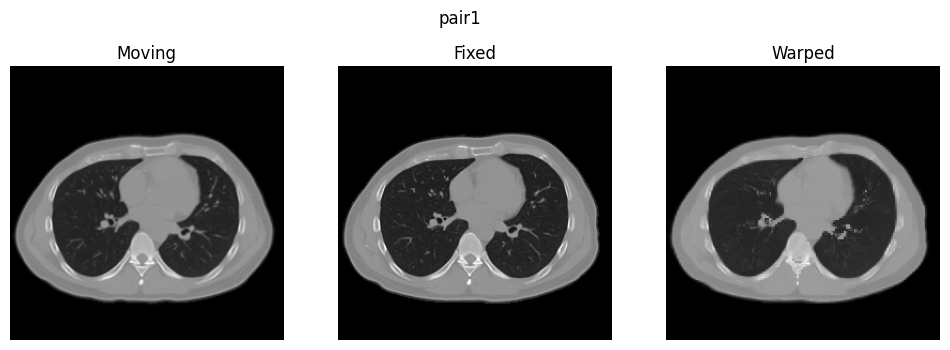

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.561137080192566e-09
pair10 | Dice=0.9510 | Jaccard=0.9065 | SSIM=0.9742 | FSIM=nan | RMSE=133.3884 | NCC=0.9922


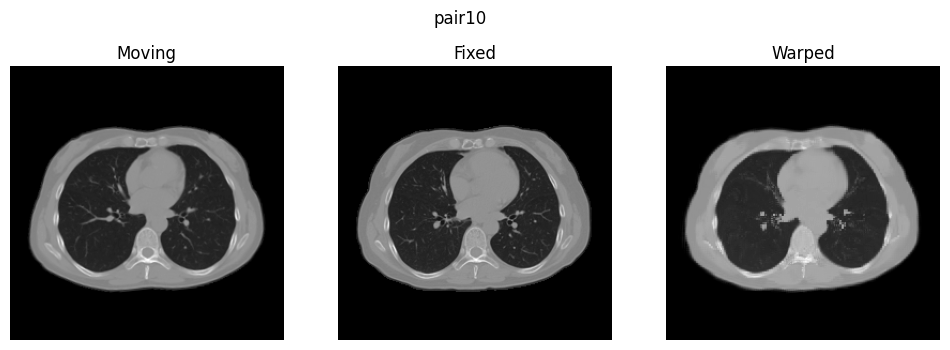

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.7939677238464355e-09
pair100 | Dice=0.9263 | Jaccard=0.8628 | SSIM=0.9704 | FSIM=nan | RMSE=153.6627 | NCC=0.9902


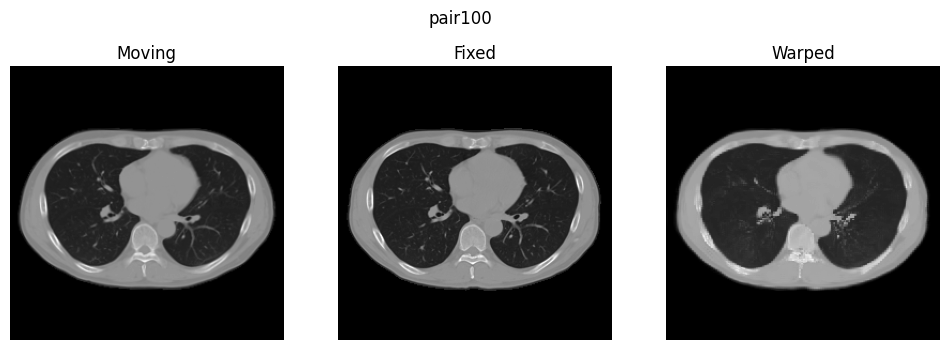

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.2118911147117615e-09
pair101 | Dice=0.9594 | Jaccard=0.9220 | SSIM=0.9720 | FSIM=nan | RMSE=145.2220 | NCC=0.9921


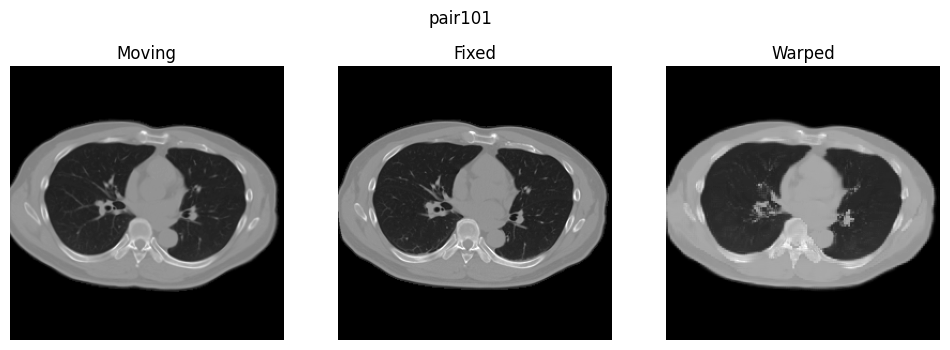

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.725290298461914e-09
pair11 | Dice=0.9407 | Jaccard=0.8881 | SSIM=0.9673 | FSIM=nan | RMSE=160.7796 | NCC=0.9897


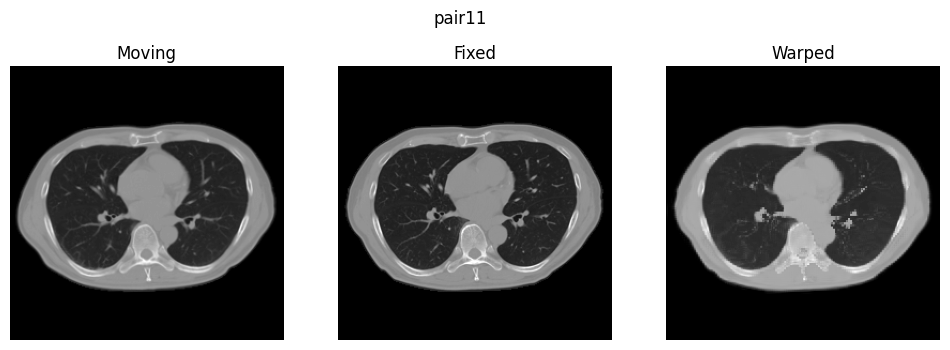

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.423782229423523e-09
pair12 | Dice=0.9680 | Jaccard=0.9381 | SSIM=0.9625 | FSIM=nan | RMSE=220.9165 | NCC=0.9812


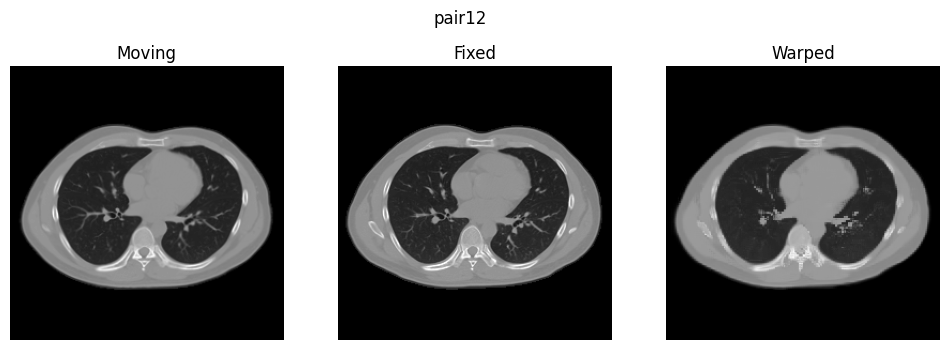

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.238689482212067e-09
pair13 | Dice=0.9242 | Jaccard=0.8591 | SSIM=0.9797 | FSIM=nan | RMSE=134.5138 | NCC=0.9917


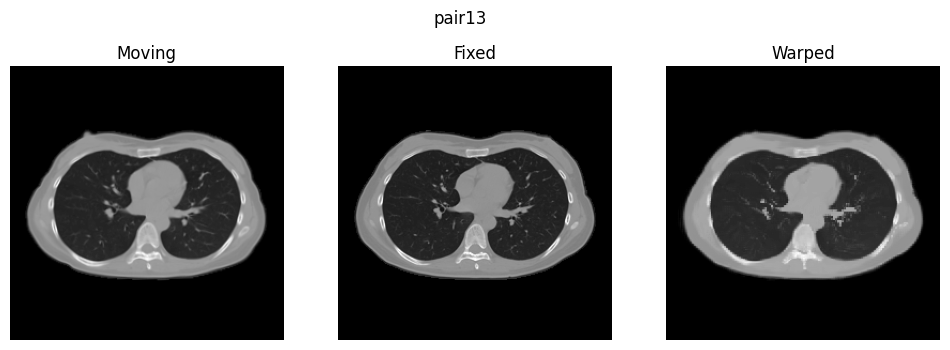

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.14321368932724e-09
pair14 | Dice=0.9460 | Jaccard=0.8976 | SSIM=0.9774 | FSIM=nan | RMSE=139.9844 | NCC=0.9917


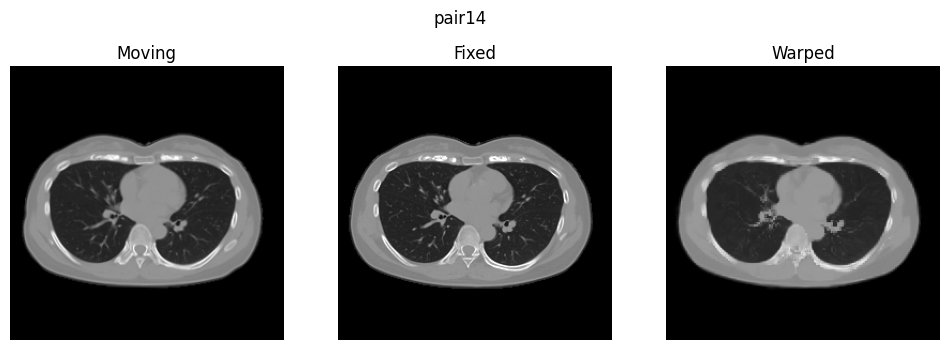

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.132743924856186e-09
pair15 | Dice=0.9558 | Jaccard=0.9153 | SSIM=0.9676 | FSIM=nan | RMSE=146.4046 | NCC=0.9917


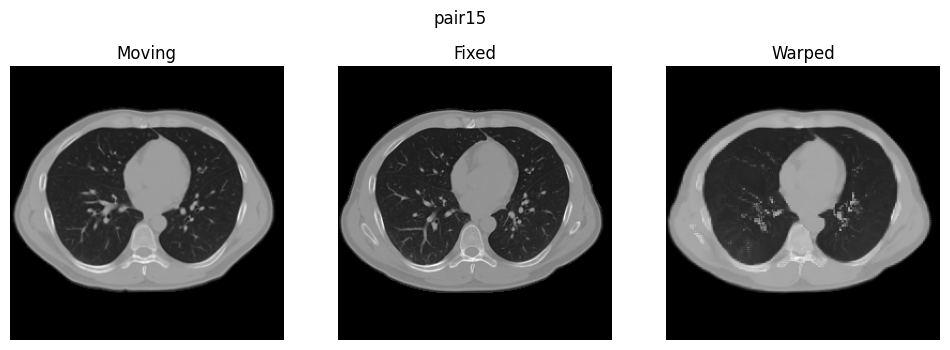

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -7.450580596923828e-09
pair16 | Dice=0.9671 | Jaccard=0.9363 | SSIM=0.9700 | FSIM=nan | RMSE=145.9542 | NCC=0.9921


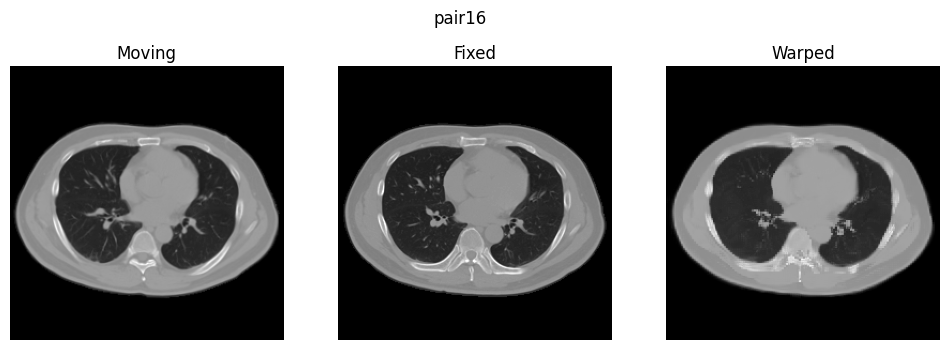

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.3551048040390015e-09
pair17 | Dice=0.9721 | Jaccard=0.9457 | SSIM=0.9619 | FSIM=nan | RMSE=179.0002 | NCC=0.9885


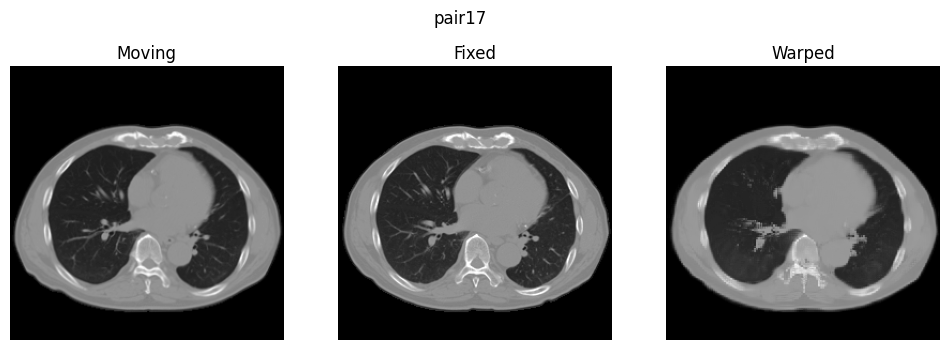

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.4924596548080444e-09
pair18 | Dice=0.9743 | Jaccard=0.9500 | SSIM=0.9482 | FSIM=nan | RMSE=208.2462 | NCC=0.9845


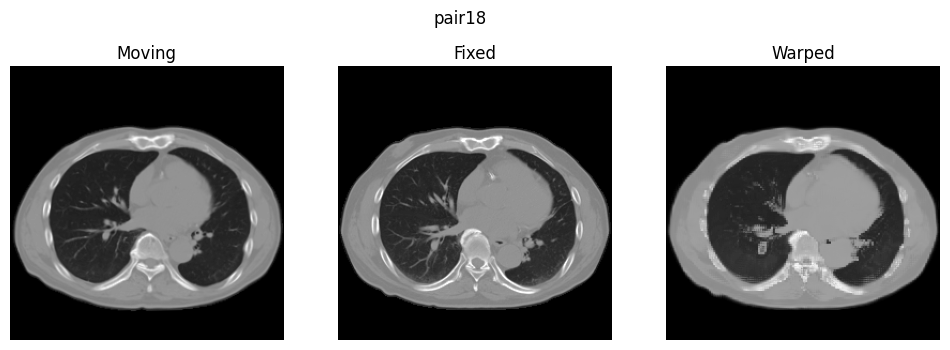

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.122274160385132e-09
pair19 | Dice=0.9684 | Jaccard=0.9387 | SSIM=0.9667 | FSIM=nan | RMSE=160.7805 | NCC=0.9905


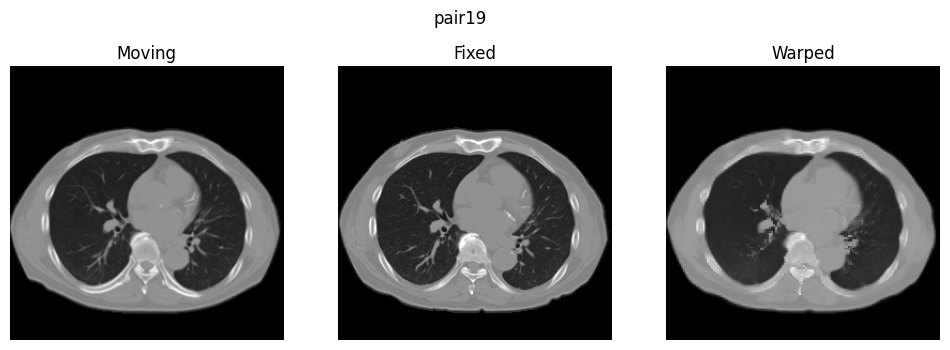

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.6566128730773926e-09
pair2 | Dice=0.9465 | Jaccard=0.8983 | SSIM=0.9727 | FSIM=nan | RMSE=145.2616 | NCC=0.9915


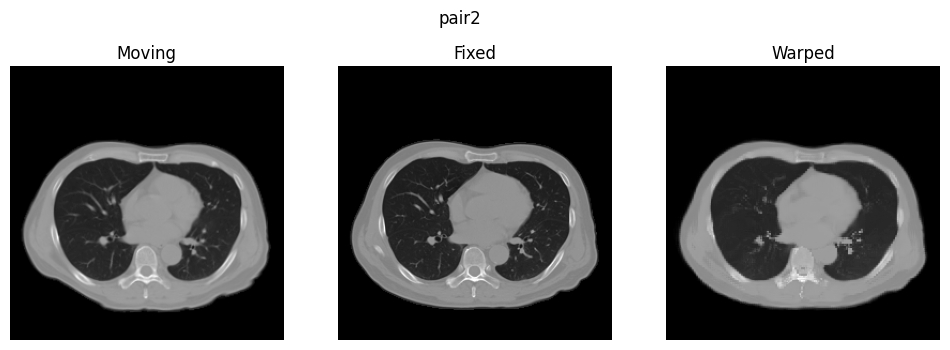

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.307366907596588e-09
pair20 | Dice=0.9861 | Jaccard=0.9727 | SSIM=0.9571 | FSIM=nan | RMSE=178.6292 | NCC=0.9886


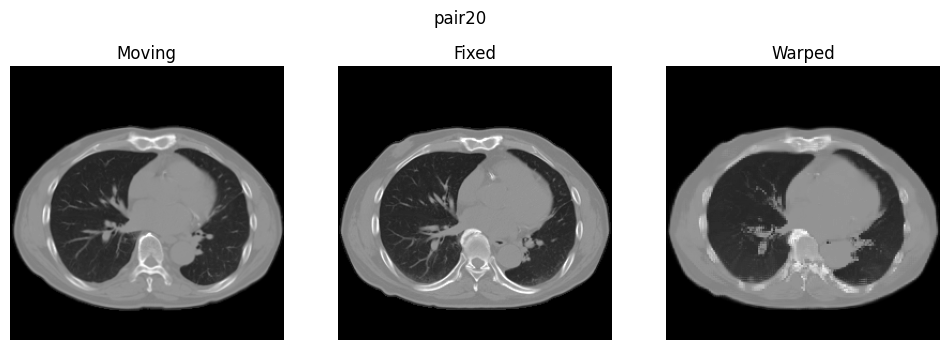

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -8.64383764564991e-09
pair21 | Dice=0.9680 | Jaccard=0.9381 | SSIM=0.9681 | FSIM=nan | RMSE=157.5504 | NCC=0.9909


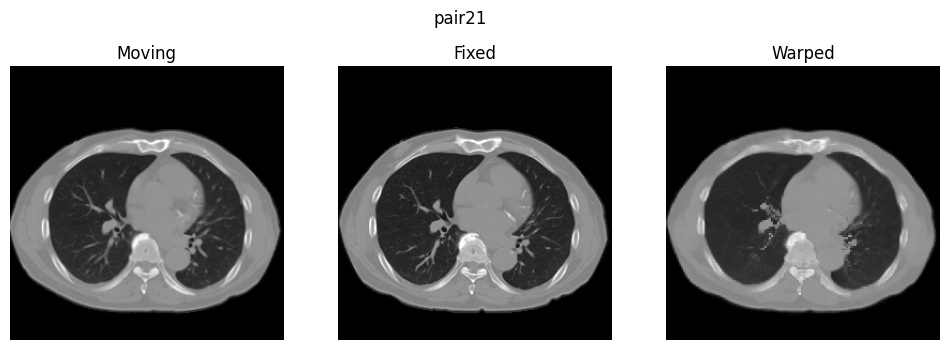

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.862645149230957e-09
pair22 | Dice=0.9675 | Jaccard=0.9371 | SSIM=0.9629 | FSIM=nan | RMSE=170.6684 | NCC=0.9893


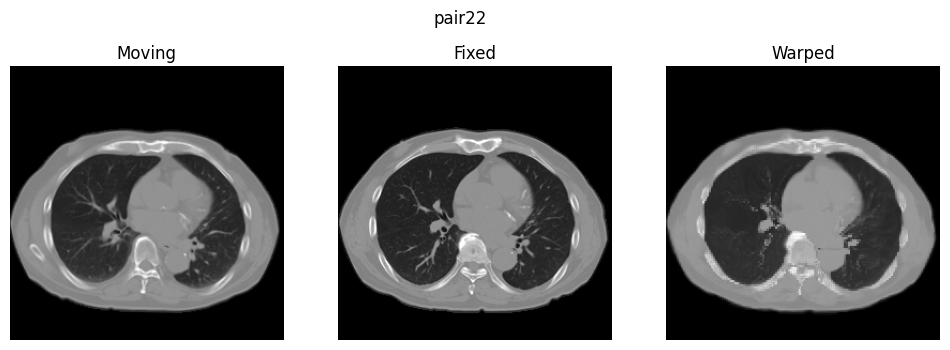

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.7462298274040222e-09
pair23 | Dice=0.9359 | Jaccard=0.8795 | SSIM=0.9719 | FSIM=nan | RMSE=156.3593 | NCC=0.9899


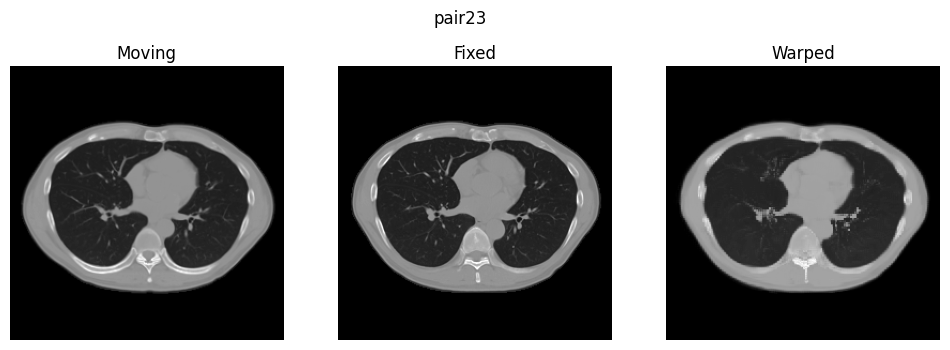

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.259629011154175e-09
pair24 | Dice=0.9426 | Jaccard=0.8915 | SSIM=0.9761 | FSIM=nan | RMSE=137.1493 | NCC=0.9919


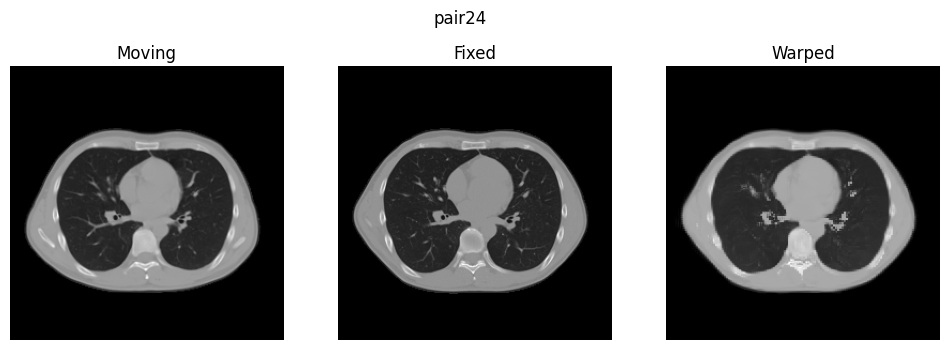

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.958120942115784e-09
pair25 | Dice=0.9613 | Jaccard=0.9254 | SSIM=0.9750 | FSIM=nan | RMSE=144.5048 | NCC=0.9915


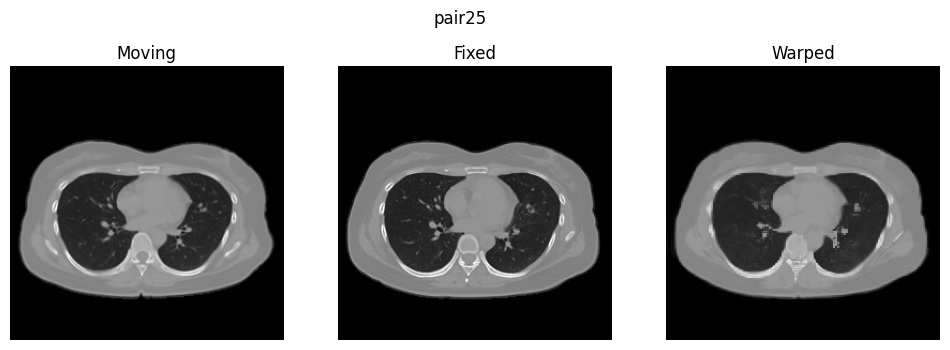

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.862645149230957e-09
pair26 | Dice=0.9573 | Jaccard=0.9180 | SSIM=0.9743 | FSIM=nan | RMSE=153.9237 | NCC=0.9901


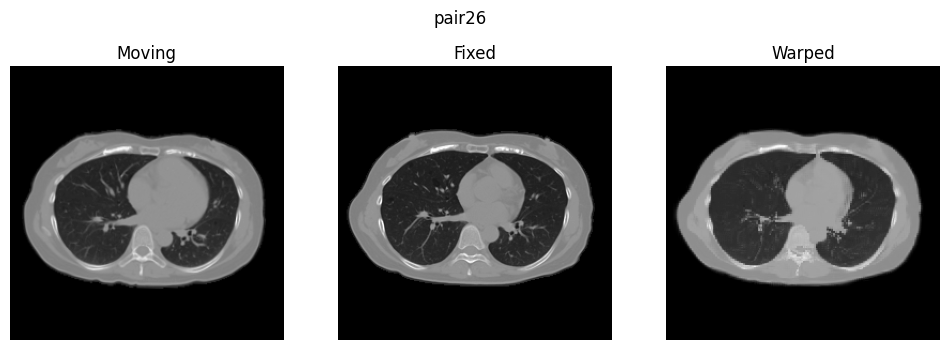

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.3283064365386963e-09
pair27 | Dice=0.9347 | Jaccard=0.8775 | SSIM=0.9701 | FSIM=nan | RMSE=156.2738 | NCC=0.9897


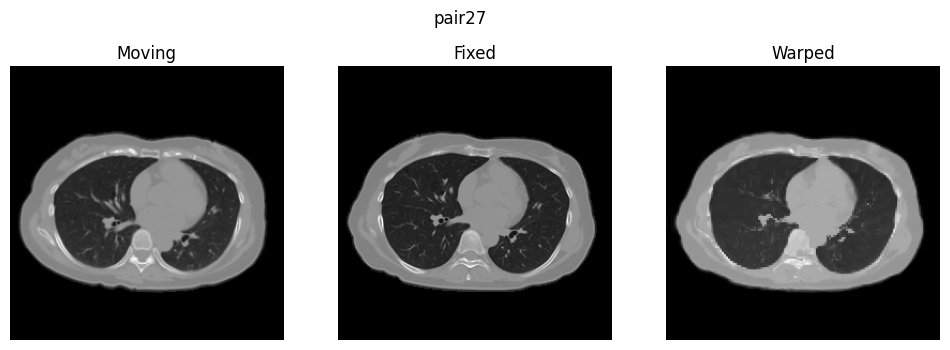

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.7939677238464355e-09
pair28 | Dice=0.9703 | Jaccard=0.9423 | SSIM=0.9762 | FSIM=nan | RMSE=144.6963 | NCC=0.9912


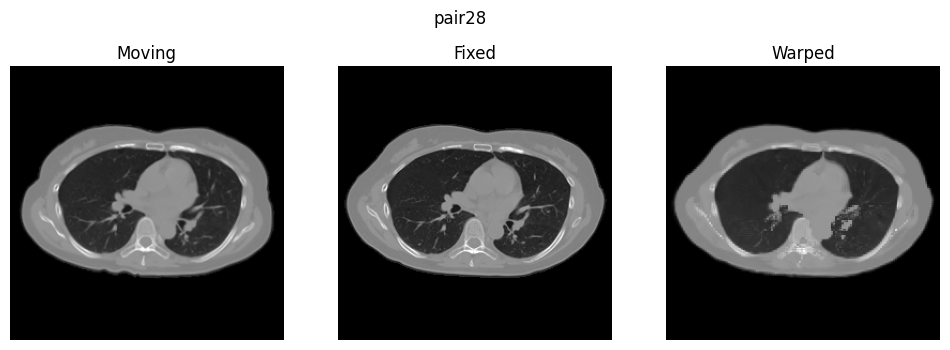

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.561137080192566e-09
pair29 | Dice=0.9453 | Jaccard=0.8963 | SSIM=0.9719 | FSIM=nan | RMSE=150.4610 | NCC=0.9904


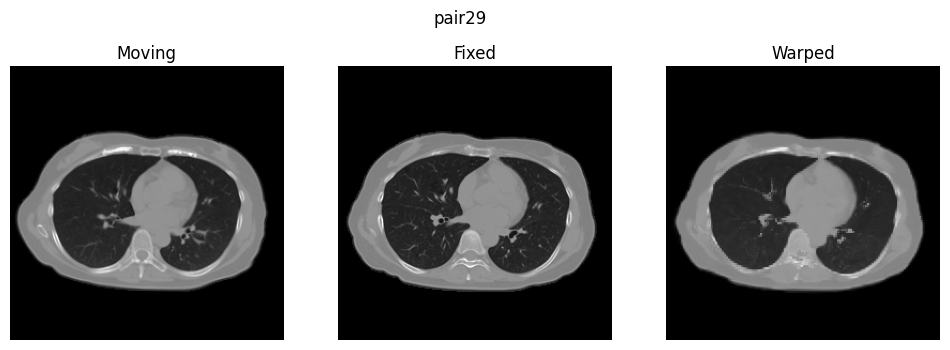

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.190951585769653e-09
pair3 | Dice=0.9744 | Jaccard=0.9501 | SSIM=0.9729 | FSIM=nan | RMSE=155.0590 | NCC=0.9909


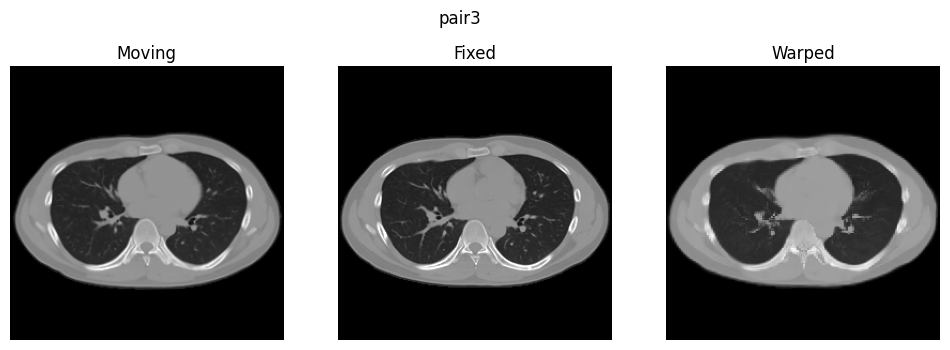

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.725290298461914e-09
pair30 | Dice=0.9697 | Jaccard=0.9412 | SSIM=0.9757 | FSIM=nan | RMSE=144.8428 | NCC=0.9912


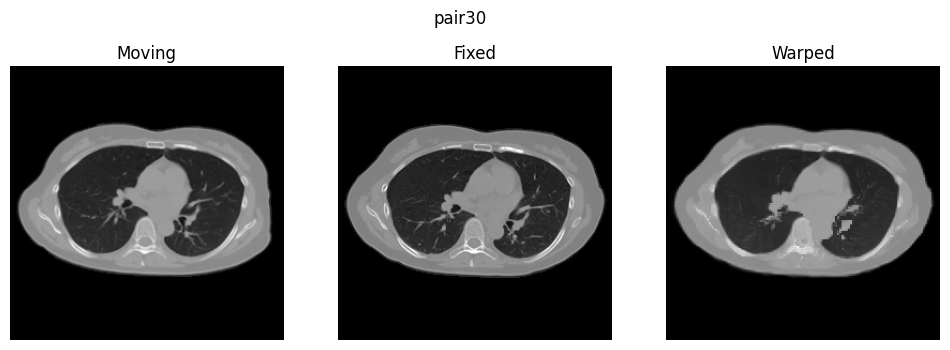

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.6775524020195007e-09
pair31 | Dice=0.9643 | Jaccard=0.9310 | SSIM=0.9697 | FSIM=nan | RMSE=165.0217 | NCC=0.9886


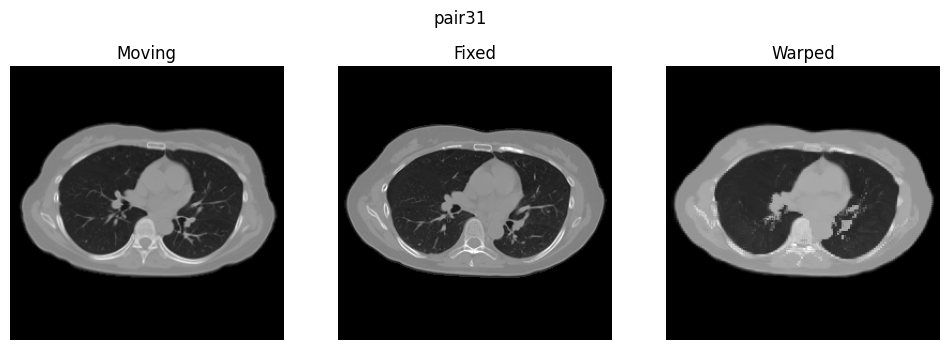

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.190951585769653e-09
pair32 | Dice=0.9829 | Jaccard=0.9664 | SSIM=0.9516 | FSIM=nan | RMSE=196.9576 | NCC=0.9852


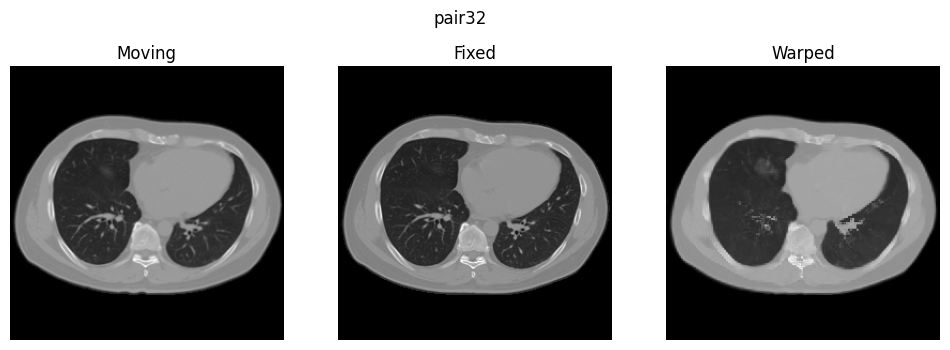

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.725290298461914e-09
pair33 | Dice=0.9785 | Jaccard=0.9579 | SSIM=0.9638 | FSIM=nan | RMSE=160.6172 | NCC=0.9902


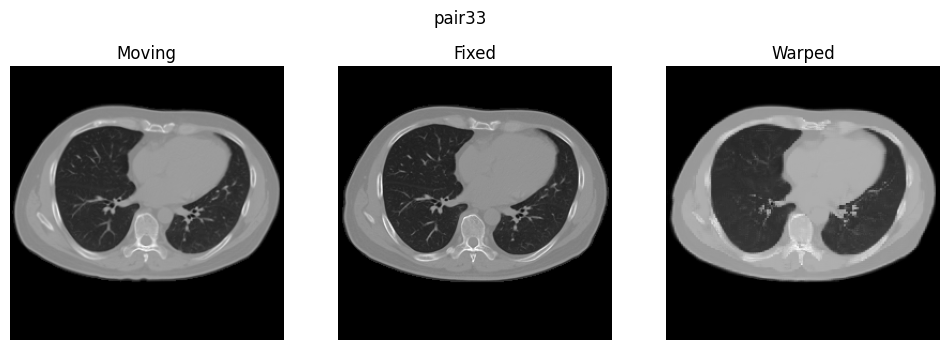

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -8.381903171539307e-09
pair34 | Dice=0.9866 | Jaccard=0.9735 | SSIM=0.9398 | FSIM=nan | RMSE=243.7249 | NCC=0.9781


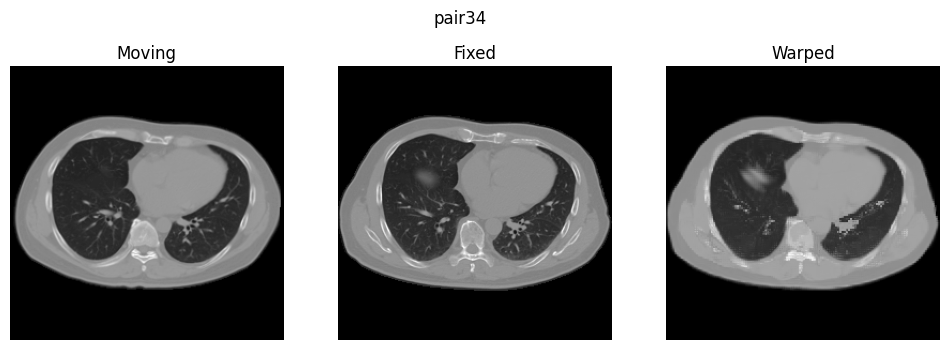

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.773028194904327e-09
pair35 | Dice=0.9789 | Jaccard=0.9588 | SSIM=0.9671 | FSIM=nan | RMSE=146.5273 | NCC=0.9919


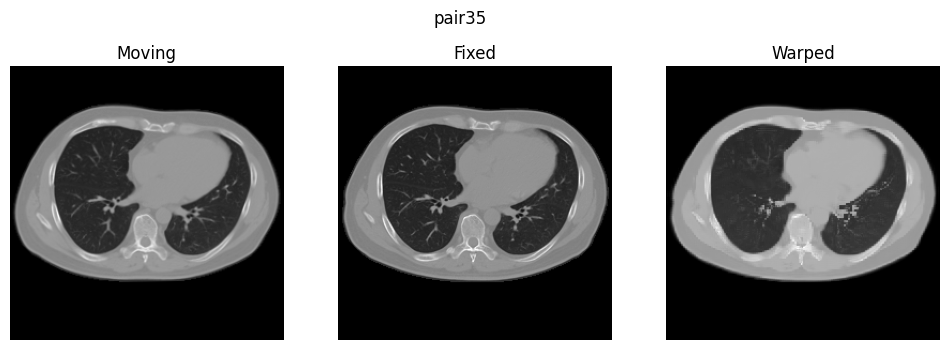

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -7.450580596923828e-09
pair36 | Dice=0.9903 | Jaccard=0.9808 | SSIM=0.9579 | FSIM=nan | RMSE=169.8157 | NCC=0.9894


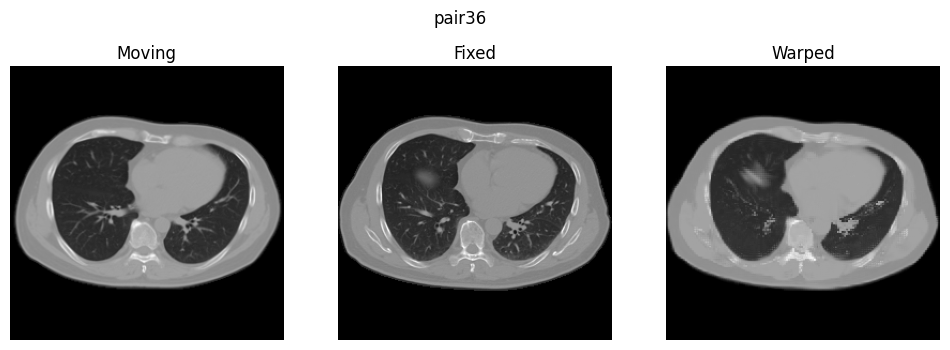

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -6.51925802230835e-09
pair37 | Dice=0.9891 | Jaccard=0.9783 | SSIM=0.9558 | FSIM=nan | RMSE=179.4839 | NCC=0.9881


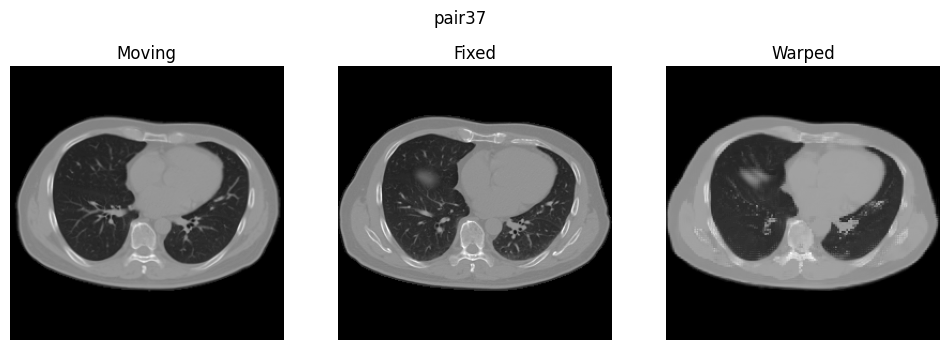

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.7939677238464355e-09
pair38 | Dice=0.9730 | Jaccard=0.9475 | SSIM=0.9681 | FSIM=nan | RMSE=161.8336 | NCC=0.9895


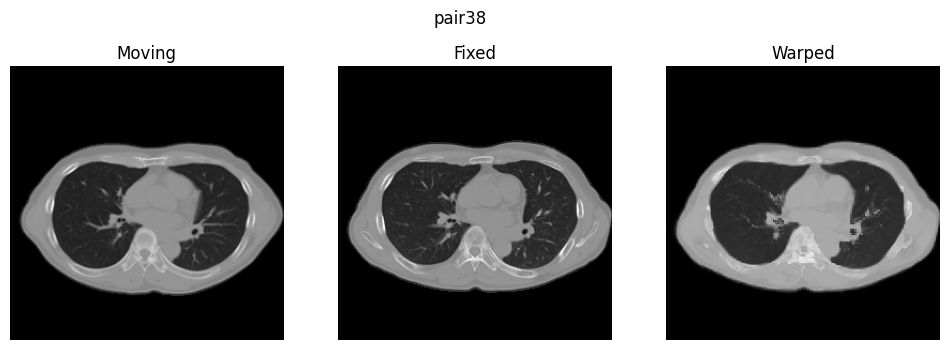

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.444721758365631e-09
pair39 | Dice=0.9719 | Jaccard=0.9453 | SSIM=0.9716 | FSIM=nan | RMSE=157.8338 | NCC=0.9894


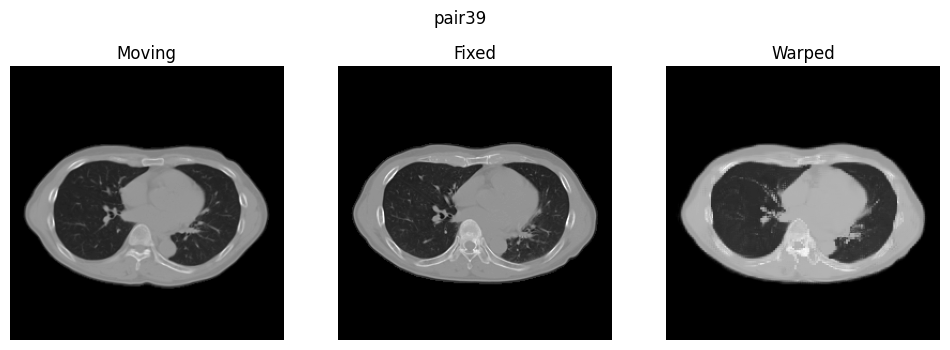

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.862645149230957e-09
pair4 | Dice=0.9318 | Jaccard=0.8723 | SSIM=0.9729 | FSIM=nan | RMSE=158.8851 | NCC=0.9902


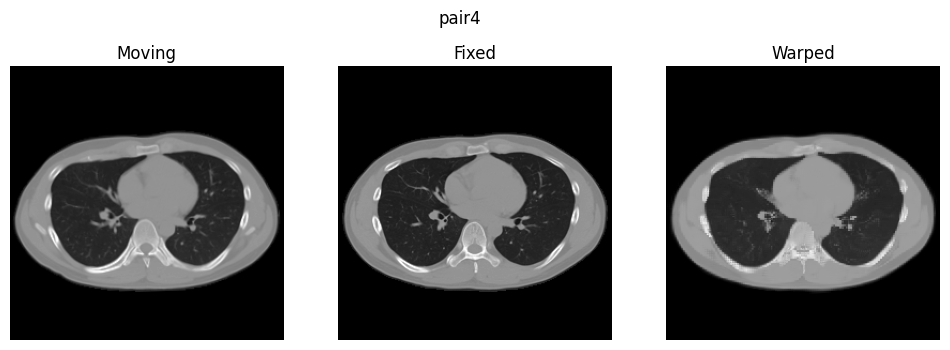

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.725290298461914e-09
pair40 | Dice=0.9778 | Jaccard=0.9566 | SSIM=0.9729 | FSIM=nan | RMSE=172.8781 | NCC=0.9872


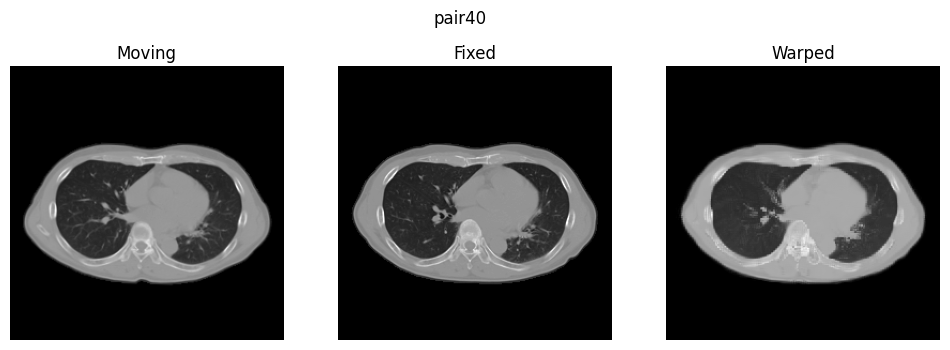

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -6.51925802230835e-09
pair41 | Dice=0.9583 | Jaccard=0.9199 | SSIM=0.9773 | FSIM=nan | RMSE=138.0061 | NCC=0.9922


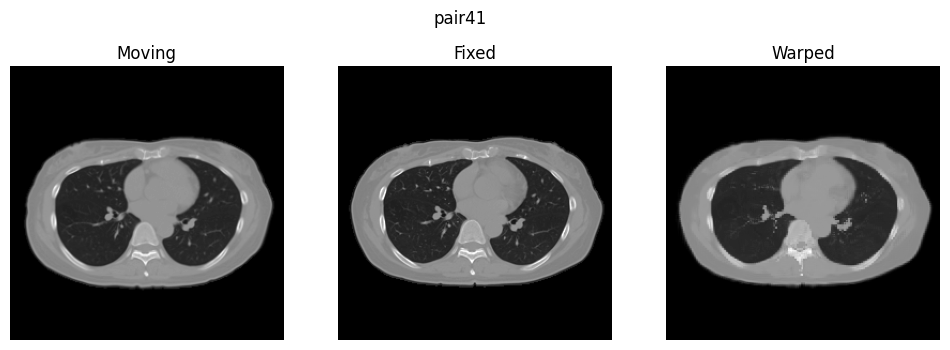

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.0745362639427185e-09
pair42 | Dice=0.9677 | Jaccard=0.9374 | SSIM=0.9689 | FSIM=nan | RMSE=143.0156 | NCC=0.9918


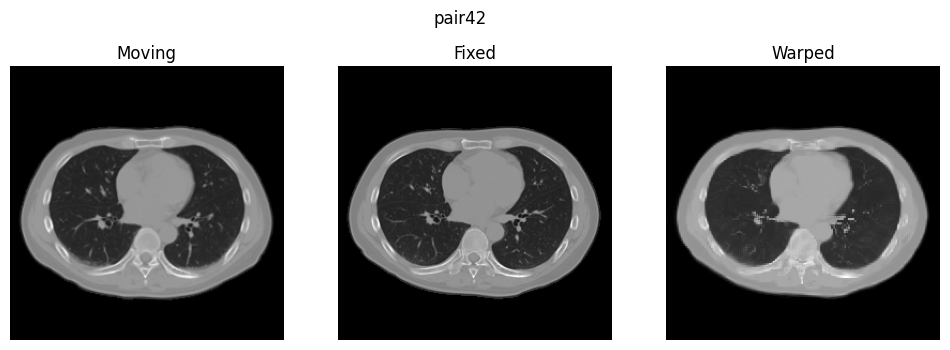

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.65253072232008e-09
pair43 | Dice=0.9820 | Jaccard=0.9646 | SSIM=0.9640 | FSIM=nan | RMSE=159.3782 | NCC=0.9902


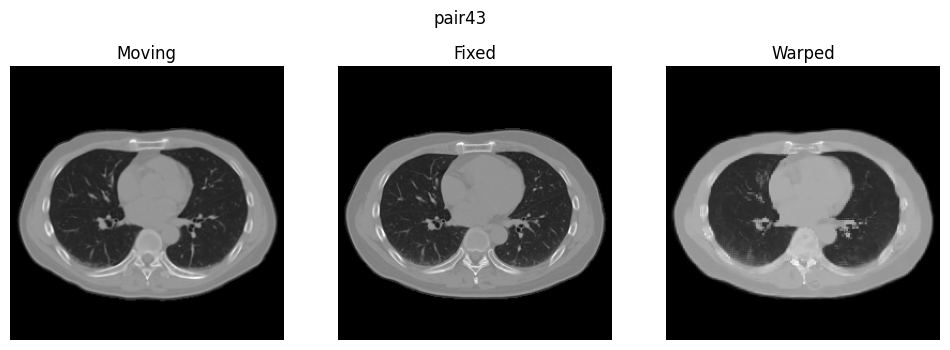

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.958120942115784e-09
pair44 | Dice=0.9821 | Jaccard=0.9649 | SSIM=0.9598 | FSIM=nan | RMSE=172.4458 | NCC=0.9885


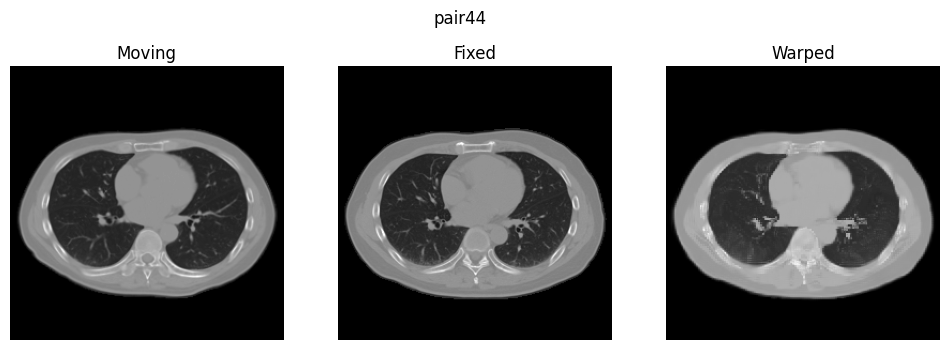

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.6298145055770874e-09
pair45 | Dice=0.9510 | Jaccard=0.9066 | SSIM=0.9733 | FSIM=nan | RMSE=139.9894 | NCC=0.9924


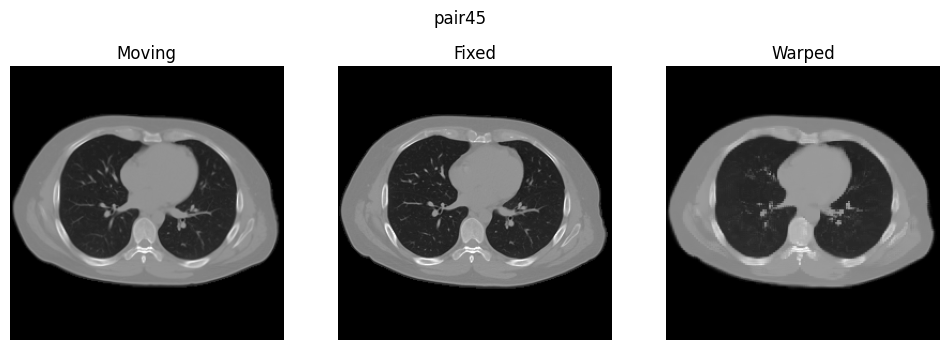

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.2014213502407074e-09
pair46 | Dice=0.9428 | Jaccard=0.8918 | SSIM=0.9588 | FSIM=nan | RMSE=313.0398 | NCC=0.9571


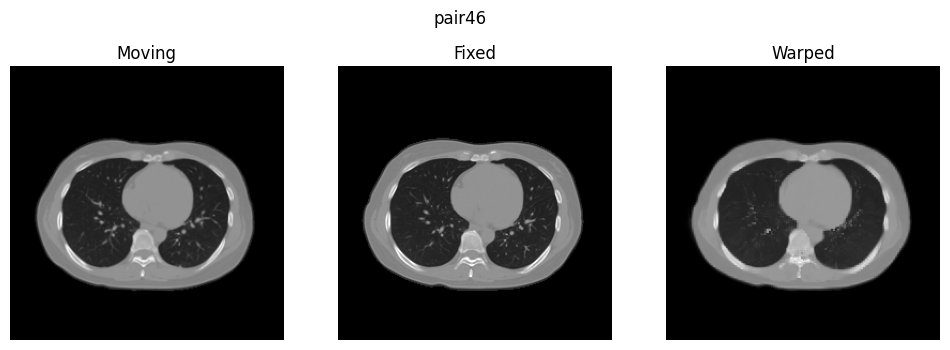

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.889443516731262e-09
pair47 | Dice=0.9457 | Jaccard=0.8969 | SSIM=0.9670 | FSIM=nan | RMSE=161.1387 | NCC=0.9897


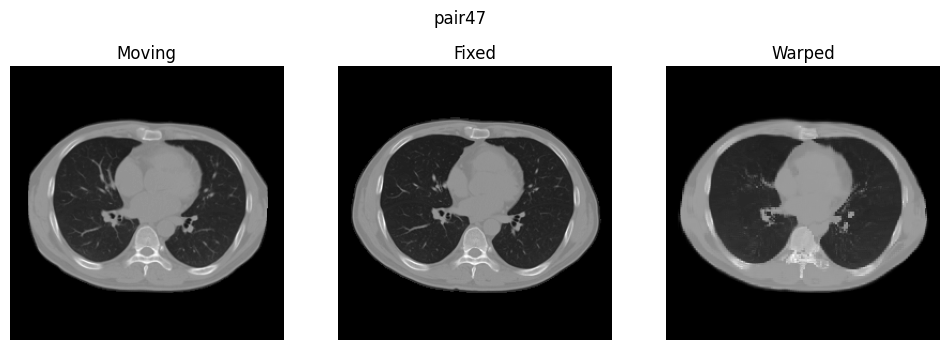

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.7782440409064293e-08
pair48 | Dice=0.9445 | Jaccard=0.8949 | SSIM=0.9667 | FSIM=nan | RMSE=179.6679 | NCC=0.9872


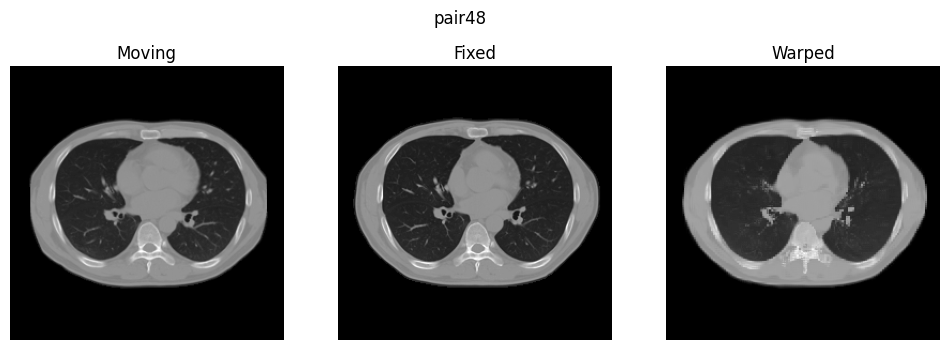

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -8.381903171539307e-09
pair49 | Dice=0.9463 | Jaccard=0.8981 | SSIM=0.9589 | FSIM=nan | RMSE=212.4886 | NCC=0.9824


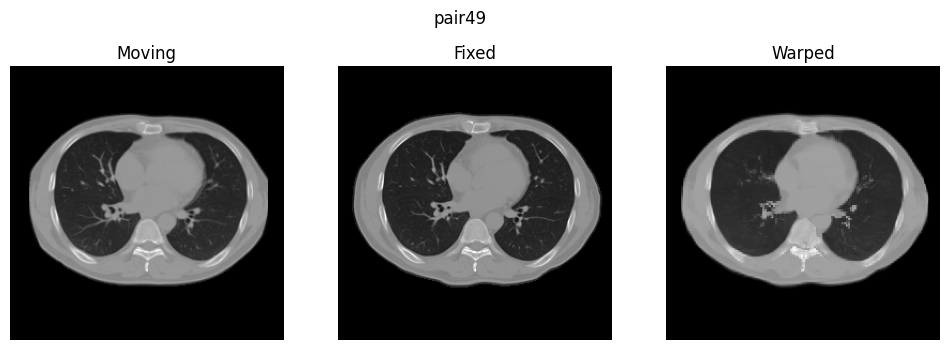

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.725290298461914e-09
pair5 | Dice=0.9315 | Jaccard=0.8718 | SSIM=0.9726 | FSIM=nan | RMSE=159.3149 | NCC=0.9902


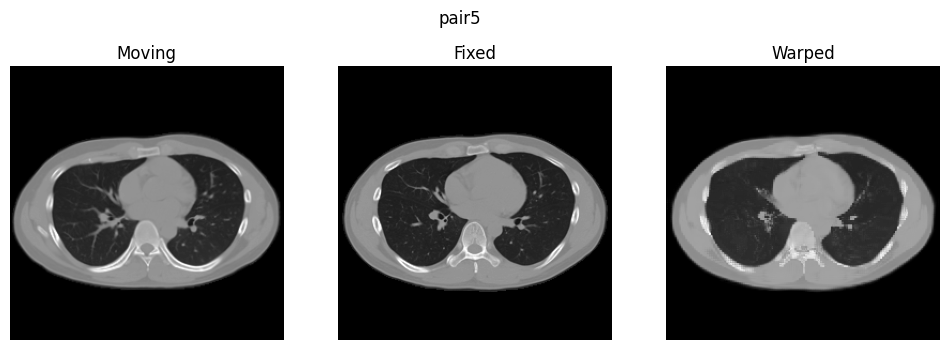

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.1059455573558807e-08
pair50 | Dice=0.9670 | Jaccard=0.9361 | SSIM=0.9663 | FSIM=nan | RMSE=175.6617 | NCC=0.9881


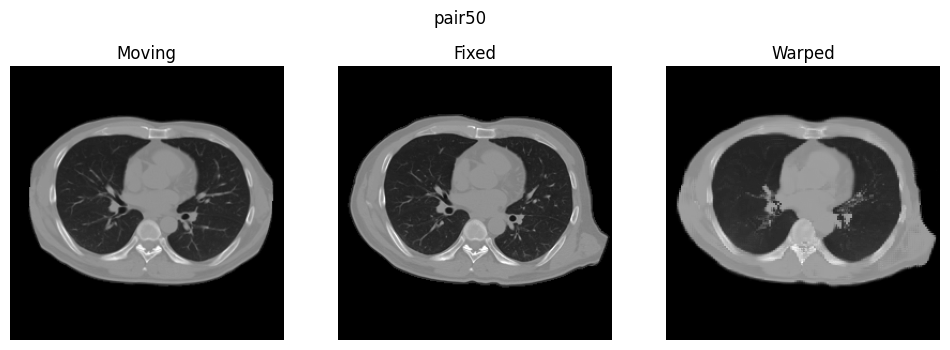

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -9.313225746154785e-09
pair51 | Dice=0.9399 | Jaccard=0.8866 | SSIM=0.9582 | FSIM=nan | RMSE=196.4688 | NCC=0.9851


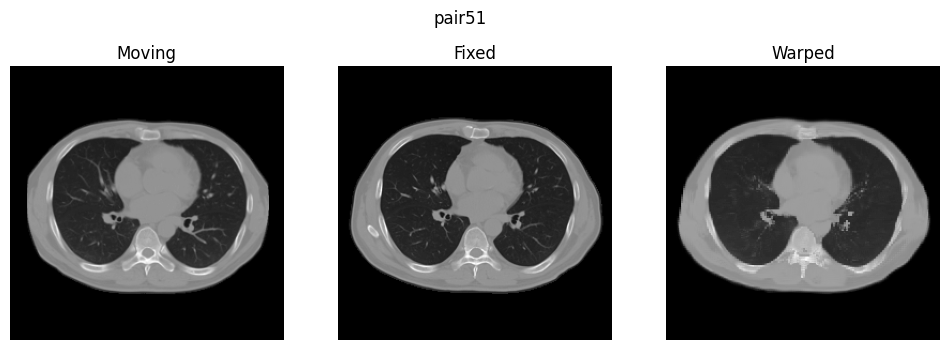

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.6088749766349792e-09
pair52 | Dice=0.9536 | Jaccard=0.9114 | SSIM=0.9728 | FSIM=nan | RMSE=156.4682 | NCC=0.9903


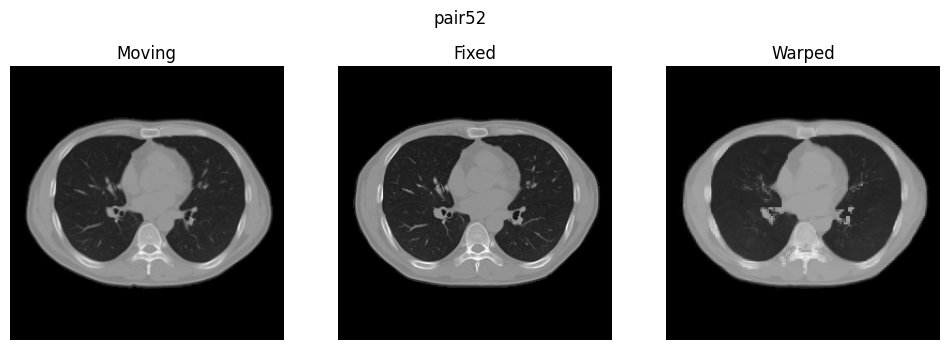

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.0640664994716644e-09
pair53 | Dice=0.9551 | Jaccard=0.9141 | SSIM=0.9695 | FSIM=nan | RMSE=166.0201 | NCC=0.9892


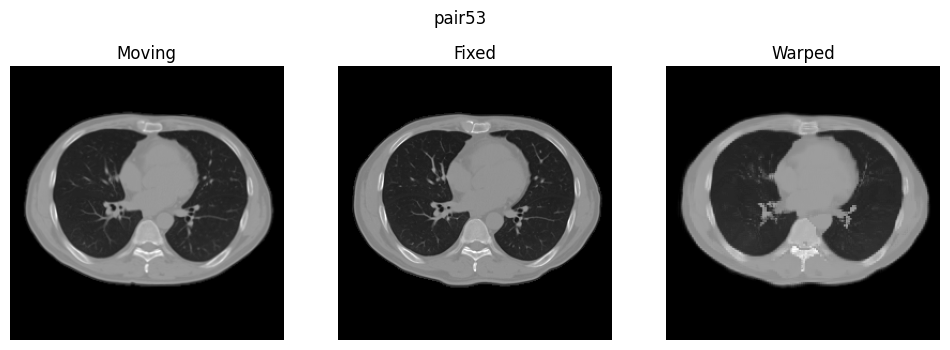

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -9.89530235528946e-09
pair54 | Dice=0.9634 | Jaccard=0.9295 | SSIM=0.9663 | FSIM=nan | RMSE=169.9033 | NCC=0.9889


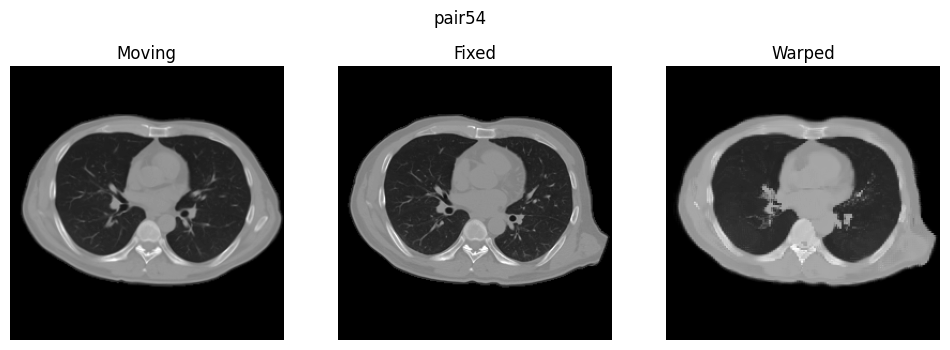

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.3283064365386963e-09
pair55 | Dice=0.9497 | Jaccard=0.9043 | SSIM=0.9677 | FSIM=nan | RMSE=165.8589 | NCC=0.9893


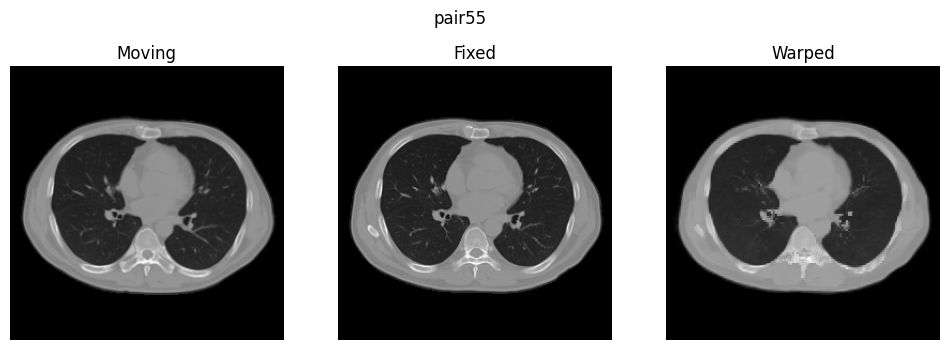

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.7834979593753815e-09
pair56 | Dice=0.9560 | Jaccard=0.9157 | SSIM=0.9707 | FSIM=nan | RMSE=158.2243 | NCC=0.9902


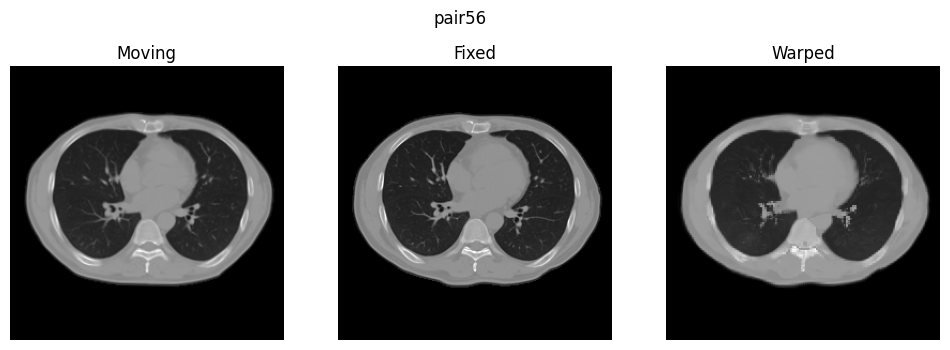

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.6566128730773926e-09
pair57 | Dice=0.9633 | Jaccard=0.9291 | SSIM=0.9672 | FSIM=nan | RMSE=164.4663 | NCC=0.9896


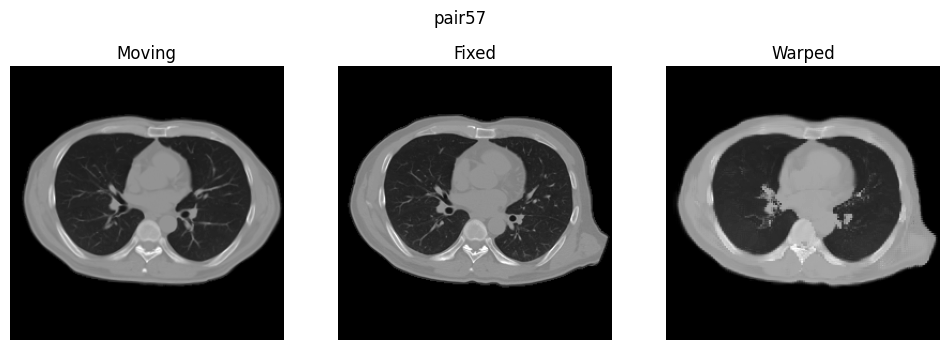

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.3551048040390015e-09
pair58 | Dice=0.9505 | Jaccard=0.9057 | SSIM=0.9676 | FSIM=nan | RMSE=162.1905 | NCC=0.9898


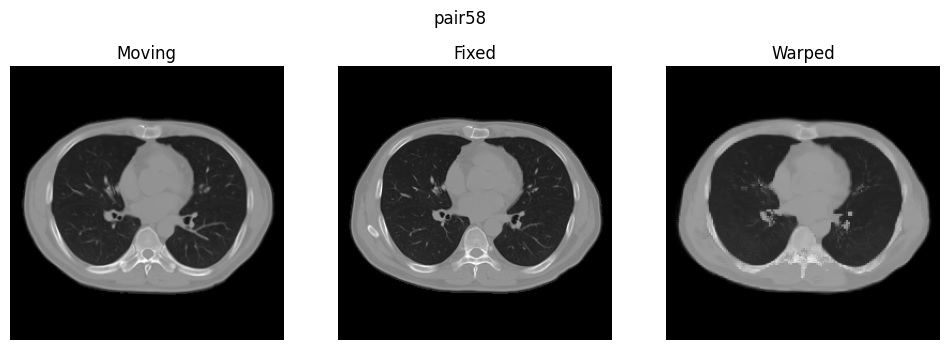

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.862645149230957e-09
pair59 | Dice=0.9632 | Jaccard=0.9290 | SSIM=0.9685 | FSIM=nan | RMSE=162.0538 | NCC=0.9899


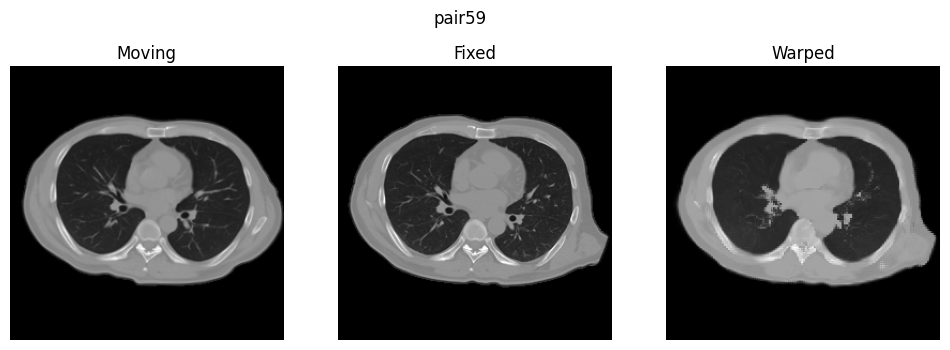

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.3283064365386963e-09
pair6 | Dice=0.9480 | Jaccard=0.9012 | SSIM=0.9669 | FSIM=nan | RMSE=151.3904 | NCC=0.9913


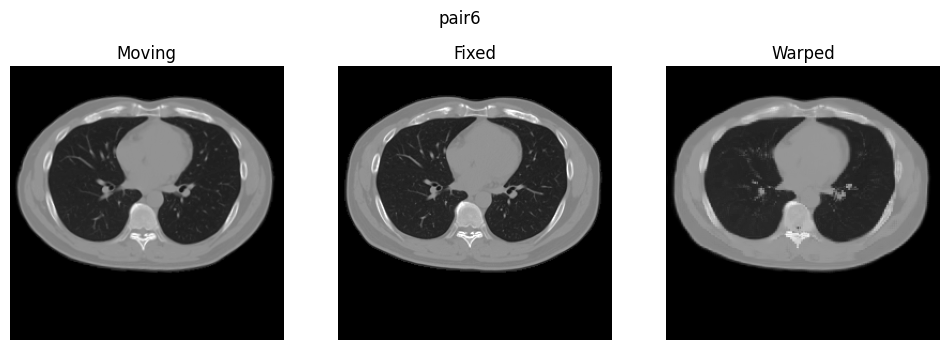

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.7939677238464355e-09
pair60 | Dice=0.9499 | Jaccard=0.9045 | SSIM=0.9690 | FSIM=nan | RMSE=157.3774 | NCC=0.9904


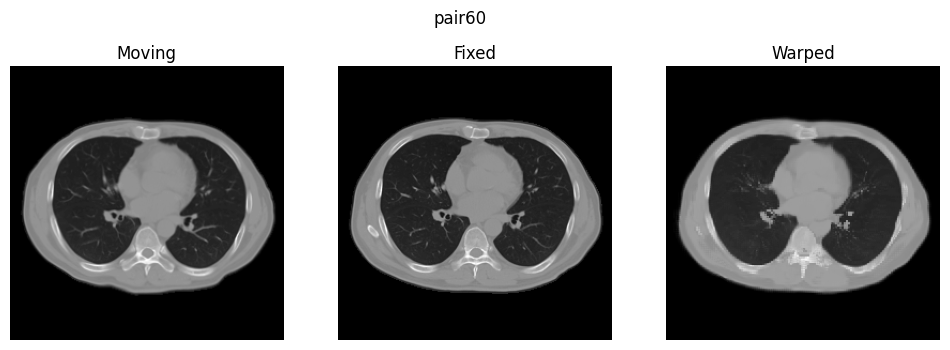

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.587935447692871e-09
pair61 | Dice=0.9390 | Jaccard=0.8850 | SSIM=0.9518 | FSIM=nan | RMSE=229.4847 | NCC=0.9795


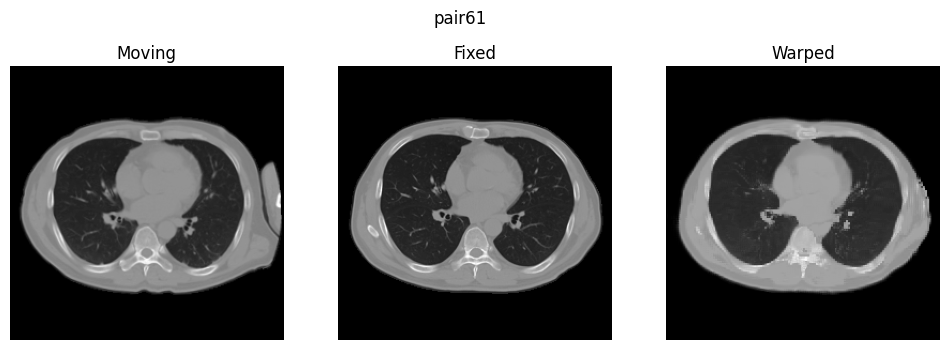

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.122274160385132e-09
pair62 | Dice=0.9568 | Jaccard=0.9172 | SSIM=0.9581 | FSIM=nan | RMSE=212.1384 | NCC=0.9824


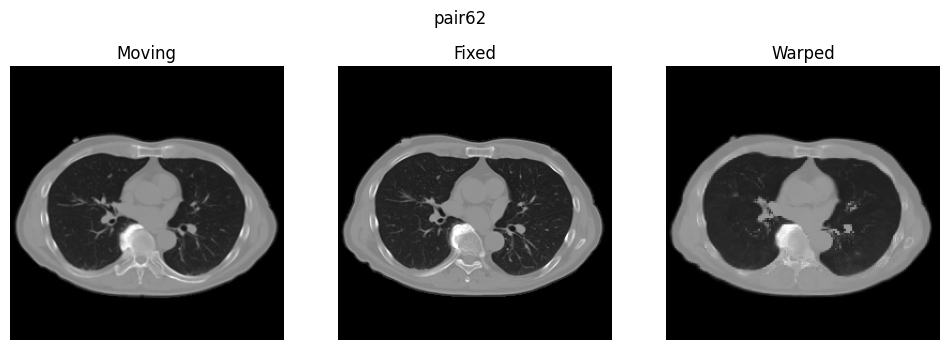

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.7939677238464355e-09
pair63 | Dice=0.9448 | Jaccard=0.8953 | SSIM=0.9708 | FSIM=nan | RMSE=149.7714 | NCC=0.9910


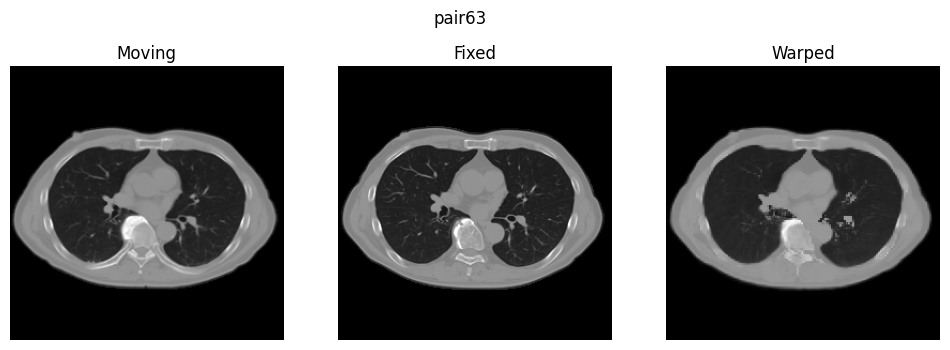

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.587935447692871e-09
pair64 | Dice=0.9411 | Jaccard=0.8887 | SSIM=0.9722 | FSIM=nan | RMSE=147.3385 | NCC=0.9913


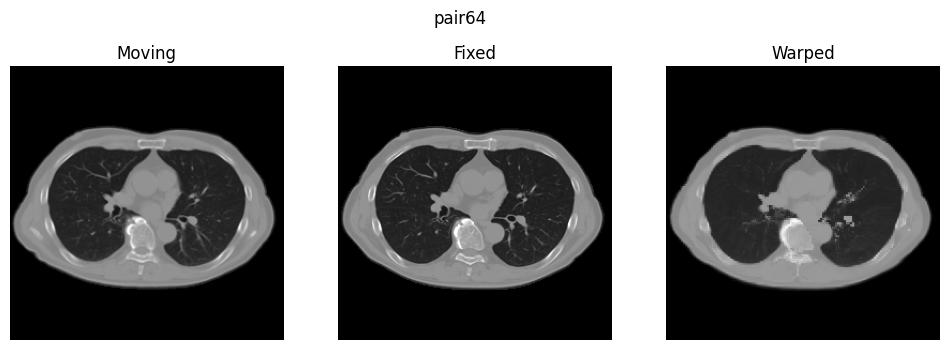

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.862645149230957e-09
pair65 | Dice=0.9331 | Jaccard=0.8746 | SSIM=0.9766 | FSIM=nan | RMSE=138.1115 | NCC=0.9918


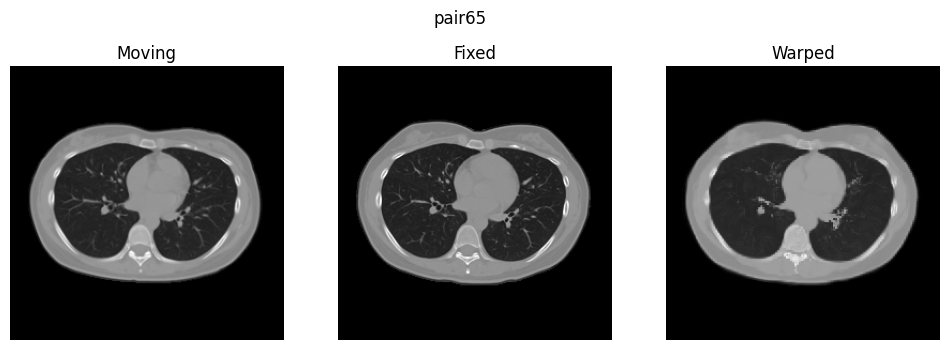

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.0745362639427185e-09
pair66 | Dice=0.9715 | Jaccard=0.9445 | SSIM=0.9490 | FSIM=nan | RMSE=274.6134 | NCC=0.9707


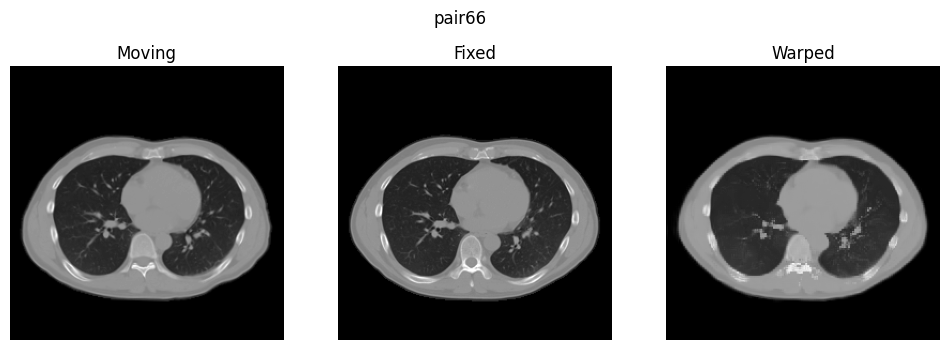

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.280568540096283e-09
pair67 | Dice=0.9673 | Jaccard=0.9367 | SSIM=0.9678 | FSIM=nan | RMSE=162.5643 | NCC=0.9903


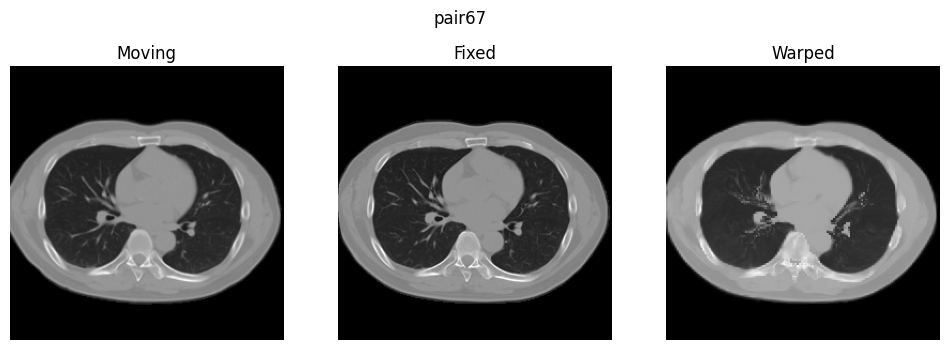

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.3283064365386963e-09
pair68 | Dice=0.9354 | Jaccard=0.8787 | SSIM=0.9726 | FSIM=nan | RMSE=155.6526 | NCC=0.9902


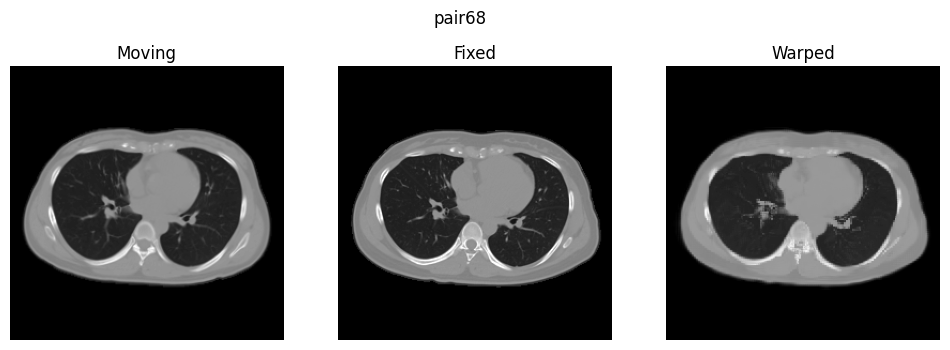

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.3551048040390015e-09
pair69 | Dice=0.9449 | Jaccard=0.8955 | SSIM=0.9740 | FSIM=nan | RMSE=144.8140 | NCC=0.9910


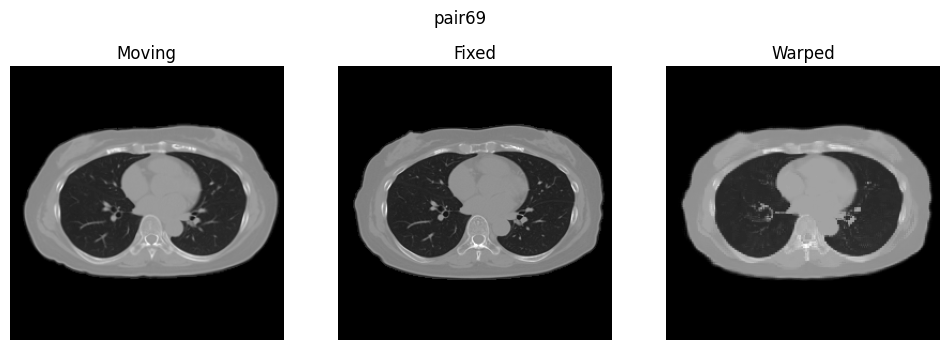

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.6193447411060333e-09
pair7 | Dice=0.9463 | Jaccard=0.8982 | SSIM=0.9666 | FSIM=nan | RMSE=162.4228 | NCC=0.9900


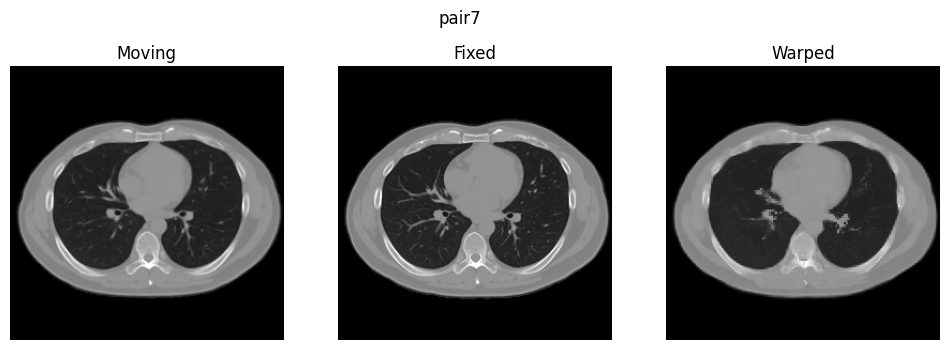

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.6338966563344e-09
pair70 | Dice=0.9373 | Jaccard=0.8820 | SSIM=0.9750 | FSIM=nan | RMSE=136.4557 | NCC=0.9919


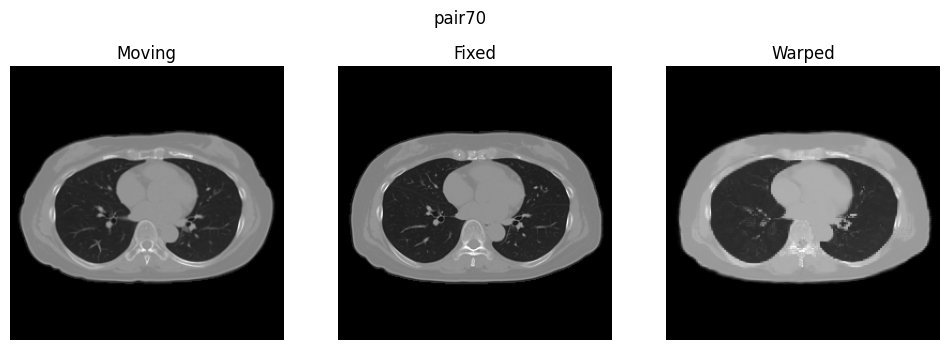

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.3283064365386963e-09
pair71 | Dice=0.9413 | Jaccard=0.8891 | SSIM=0.9774 | FSIM=nan | RMSE=132.1771 | NCC=0.9924


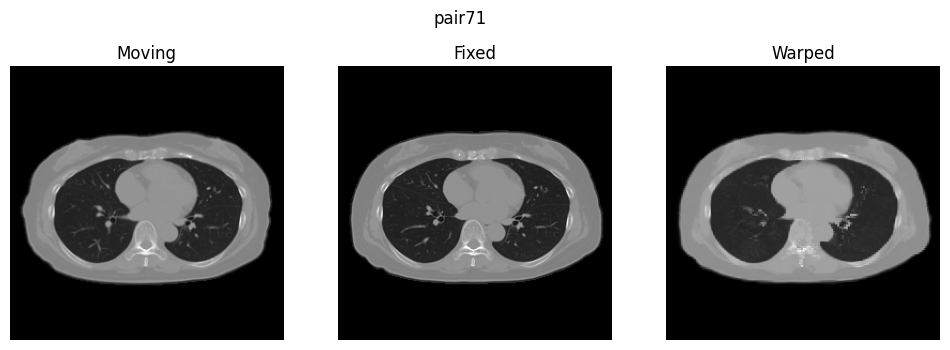

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.444721758365631e-09
pair72 | Dice=0.9630 | Jaccard=0.9287 | SSIM=0.9236 | FSIM=nan | RMSE=381.3285 | NCC=0.9468


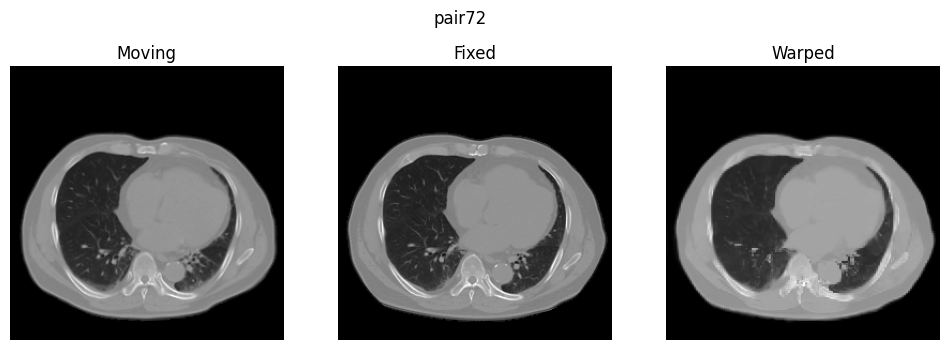

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -9.778887033462524e-09
pair73 | Dice=0.9759 | Jaccard=0.9530 | SSIM=0.9509 | FSIM=nan | RMSE=198.9180 | NCC=0.9853


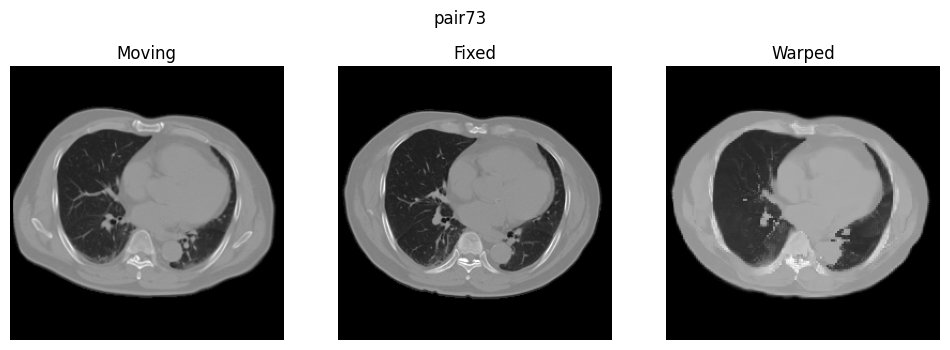

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -8.149072527885437e-09
pair74 | Dice=0.9783 | Jaccard=0.9576 | SSIM=0.9652 | FSIM=nan | RMSE=153.6927 | NCC=0.9913


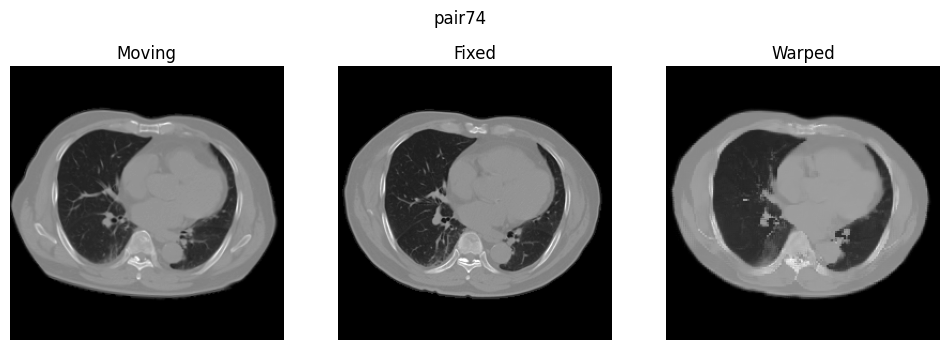

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.3283064365386963e-09
pair75 | Dice=0.9355 | Jaccard=0.8789 | SSIM=0.9744 | FSIM=nan | RMSE=156.1187 | NCC=0.9901


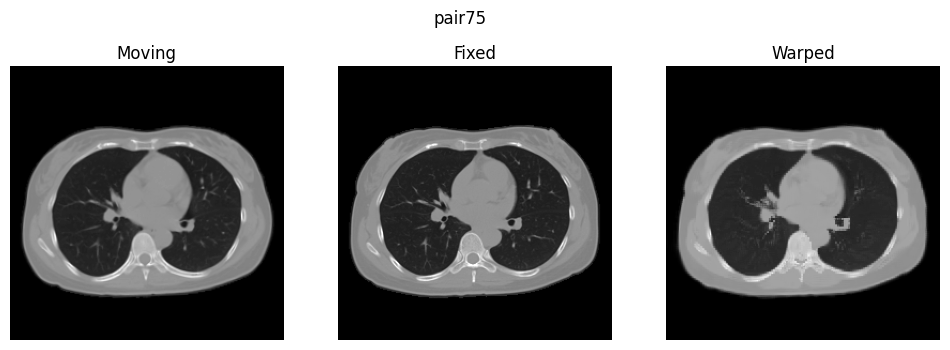

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.561137080192566e-09
pair76 | Dice=0.9361 | Jaccard=0.8799 | SSIM=0.9744 | FSIM=nan | RMSE=150.6977 | NCC=0.9905


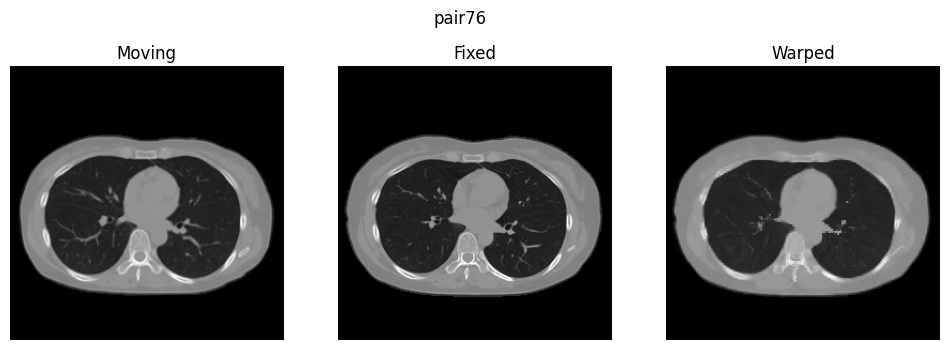

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.2118911147117615e-09
pair77 | Dice=0.9341 | Jaccard=0.8764 | SSIM=0.8936 | FSIM=nan | RMSE=558.4403 | NCC=0.8878


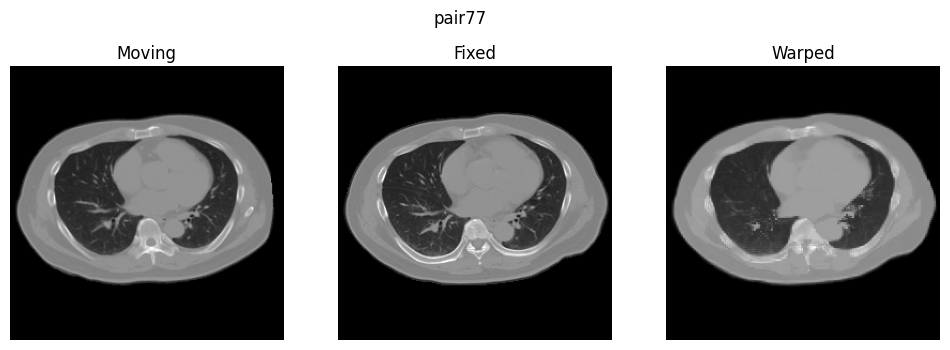

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.190951585769653e-09
pair78 | Dice=0.9114 | Jaccard=0.8372 | SSIM=0.8702 | FSIM=nan | RMSE=641.4648 | NCC=0.8565


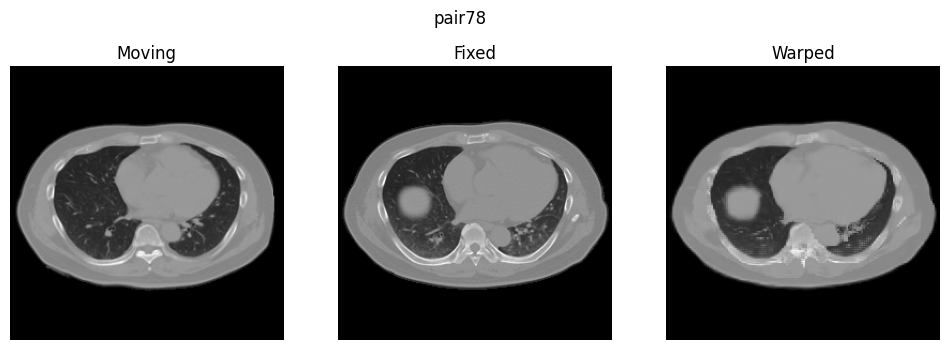

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.862645149230957e-09
pair79 | Dice=0.9324 | Jaccard=0.8733 | SSIM=0.9091 | FSIM=nan | RMSE=509.4031 | NCC=0.9054


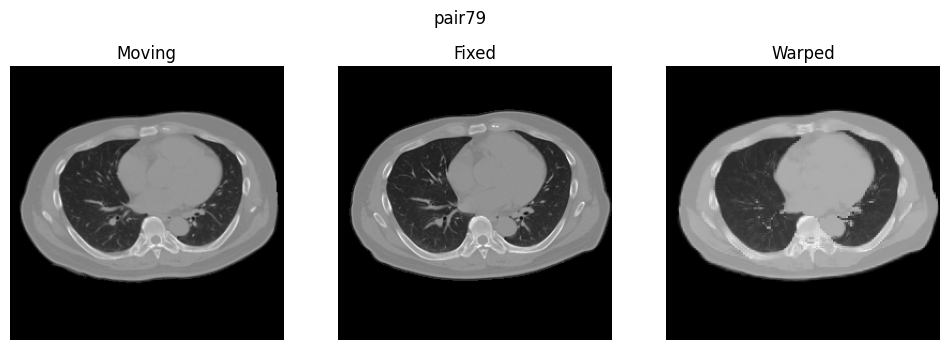

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.6566128730773926e-09
pair8 | Dice=0.9455 | Jaccard=0.8966 | SSIM=0.9662 | FSIM=nan | RMSE=168.0113 | NCC=0.9893


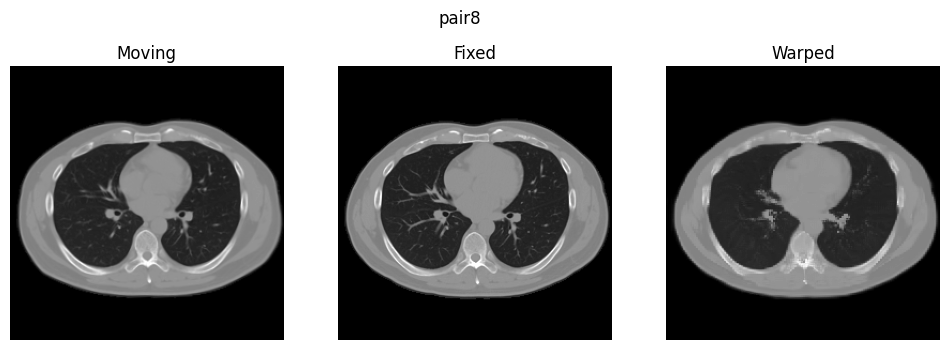

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.0745362639427185e-09
pair80 | Dice=0.9227 | Jaccard=0.8564 | SSIM=0.8897 | FSIM=nan | RMSE=592.9688 | NCC=0.8764


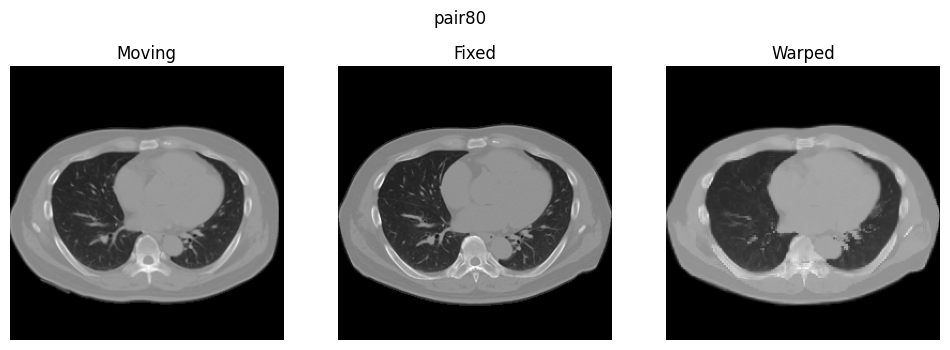

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.259629011154175e-09
pair81 | Dice=0.9922 | Jaccard=0.9845 | SSIM=0.9638 | FSIM=nan | RMSE=157.9296 | NCC=0.9909


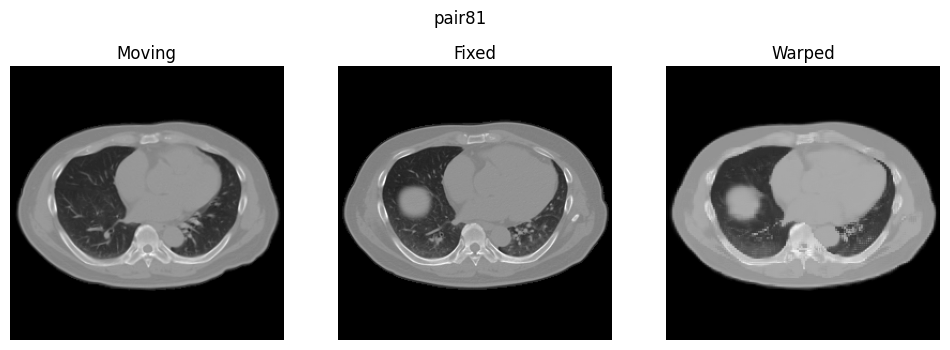

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.3969838619232178e-09
pair82 | Dice=0.9780 | Jaccard=0.9570 | SSIM=0.9642 | FSIM=nan | RMSE=180.3555 | NCC=0.9879


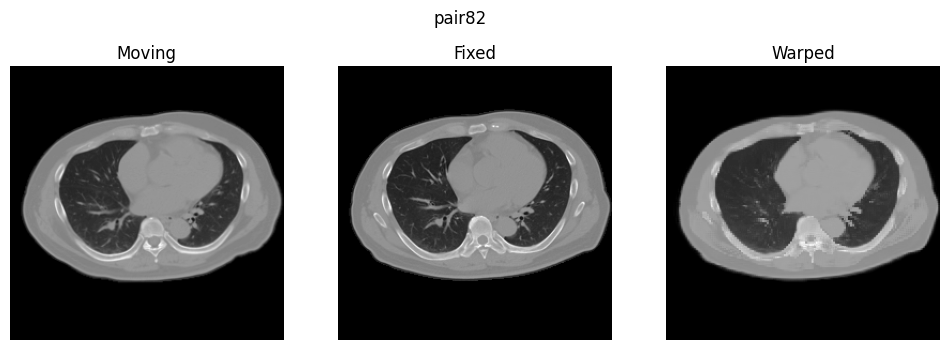

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.725290298461914e-09
pair83 | Dice=0.9835 | Jaccard=0.9675 | SSIM=0.9630 | FSIM=nan | RMSE=185.4631 | NCC=0.9874


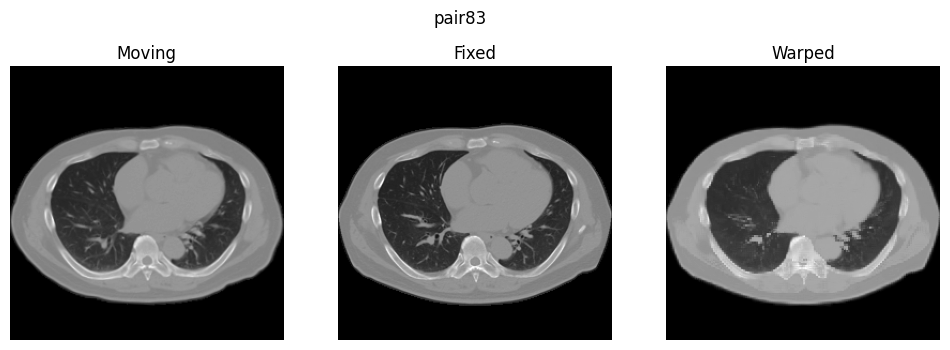

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.190951585769653e-09
pair84 | Dice=0.9786 | Jaccard=0.9582 | SSIM=0.9640 | FSIM=nan | RMSE=178.8814 | NCC=0.9881


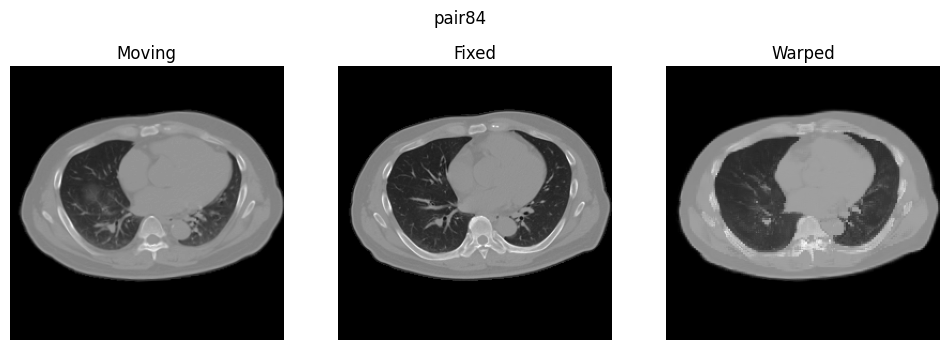

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -1.862645149230957e-09
pair85 | Dice=0.9847 | Jaccard=0.9698 | SSIM=0.9625 | FSIM=nan | RMSE=180.3488 | NCC=0.9881


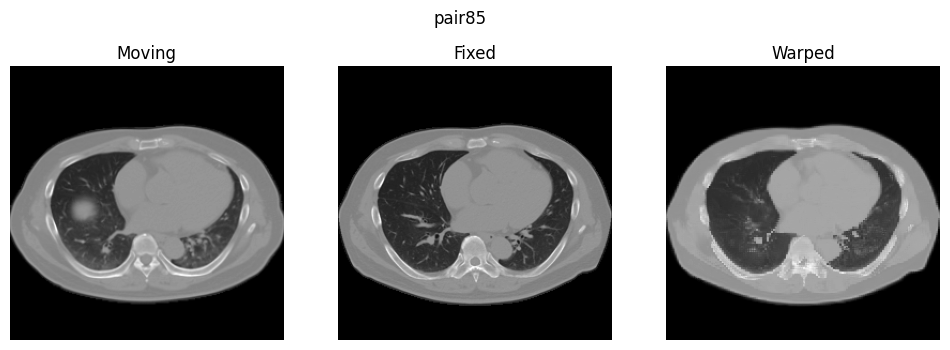

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.423782229423523e-09
pair86 | Dice=0.9822 | Jaccard=0.9650 | SSIM=0.9606 | FSIM=nan | RMSE=184.9847 | NCC=0.9875


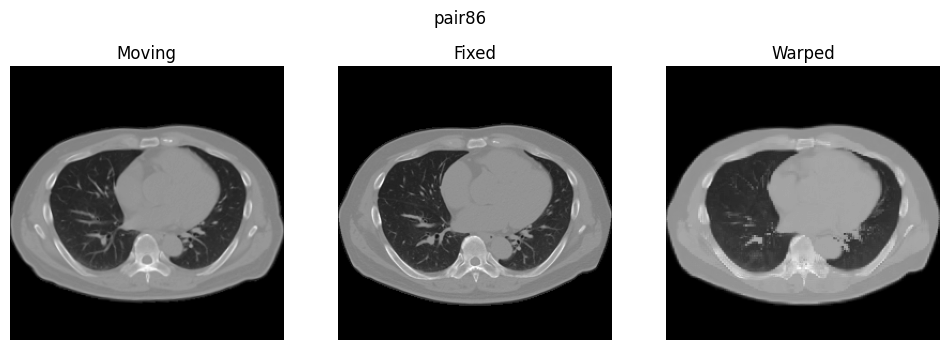

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.7939677238464355e-09
pair87 | Dice=0.9729 | Jaccard=0.9471 | SSIM=0.9683 | FSIM=nan | RMSE=150.2350 | NCC=0.9913


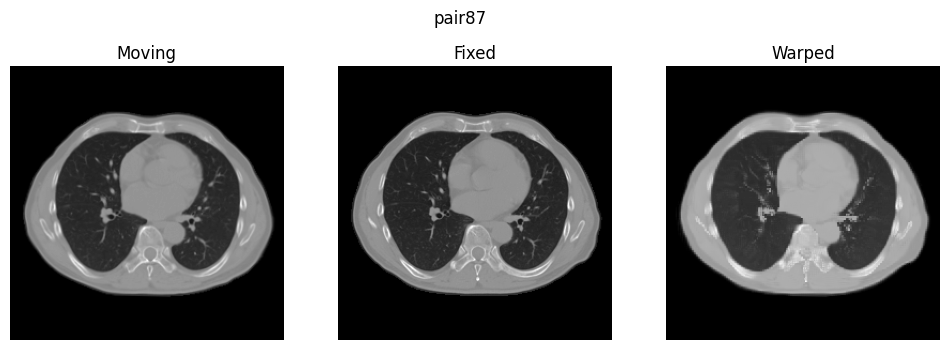

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.587935447692871e-09
pair88 | Dice=0.9766 | Jaccard=0.9543 | SSIM=0.9710 | FSIM=nan | RMSE=140.6826 | NCC=0.9923


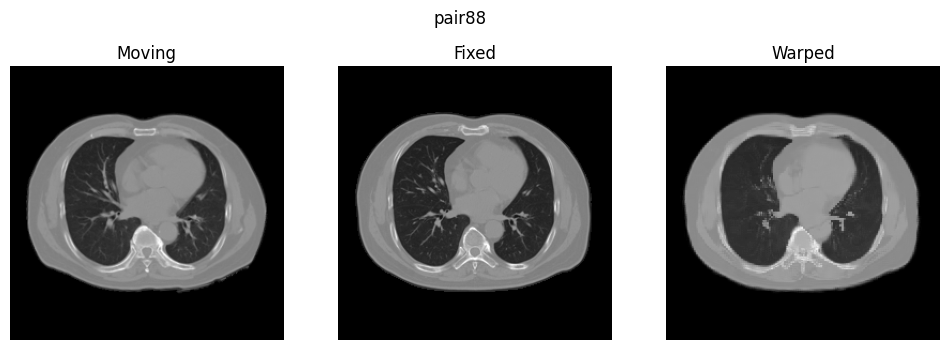

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -4.190951585769653e-09
pair89 | Dice=0.9781 | Jaccard=0.9571 | SSIM=0.9281 | FSIM=nan | RMSE=325.7123 | NCC=0.9606


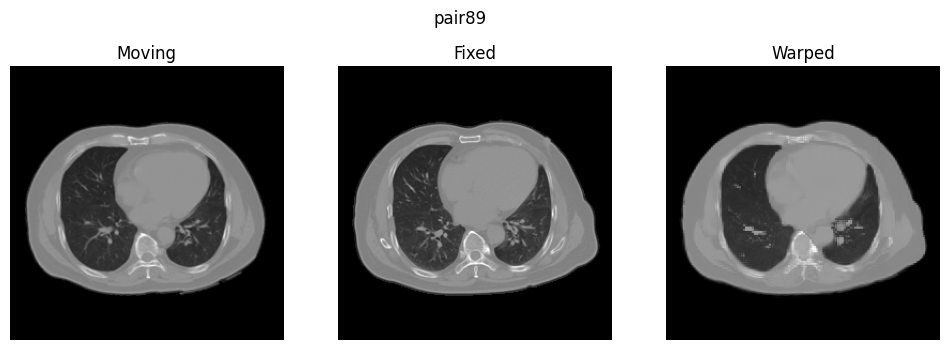

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.026798367500305e-09
pair9 | Dice=0.9661 | Jaccard=0.9345 | SSIM=0.9755 | FSIM=nan | RMSE=144.7916 | NCC=0.9912


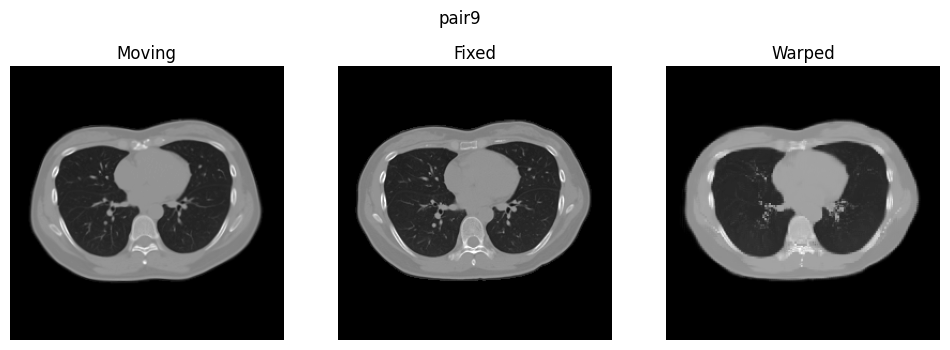

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.4924596548080444e-09
pair90 | Dice=0.9667 | Jaccard=0.9355 | SSIM=0.9155 | FSIM=nan | RMSE=385.6338 | NCC=0.9451


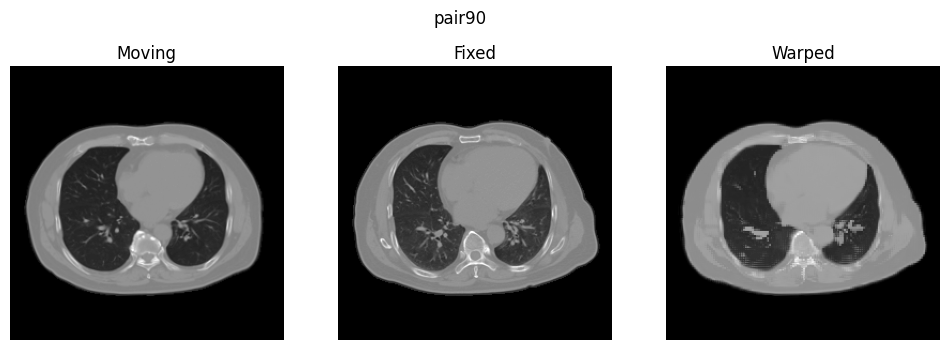

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.561137080192566e-09
pair91 | Dice=0.9764 | Jaccard=0.9539 | SSIM=0.9729 | FSIM=nan | RMSE=163.1738 | NCC=0.9896


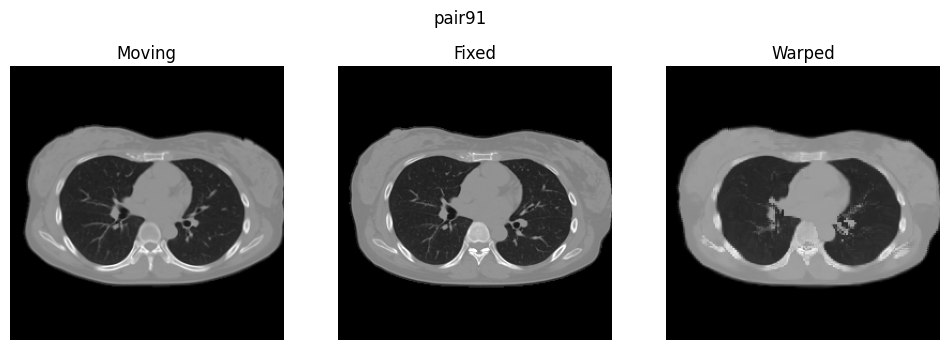

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.3760443329811096e-09
pair92 | Dice=0.9540 | Jaccard=0.9121 | SSIM=0.9673 | FSIM=nan | RMSE=170.3367 | NCC=0.9889


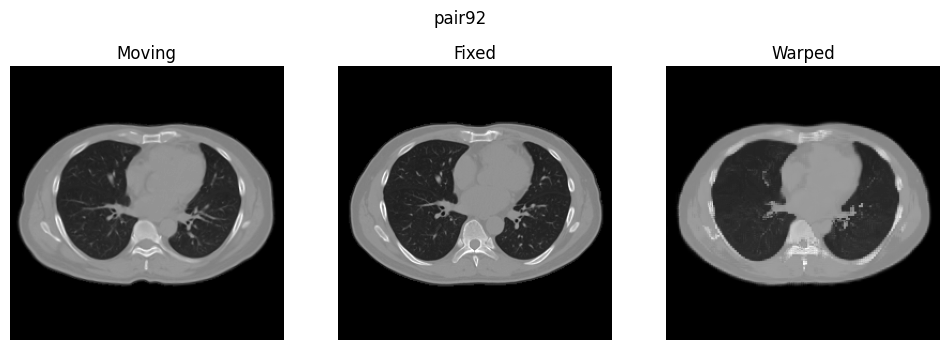

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.7939677238464355e-09
pair93 | Dice=0.9317 | Jaccard=0.8721 | SSIM=0.9741 | FSIM=nan | RMSE=141.9916 | NCC=0.9919


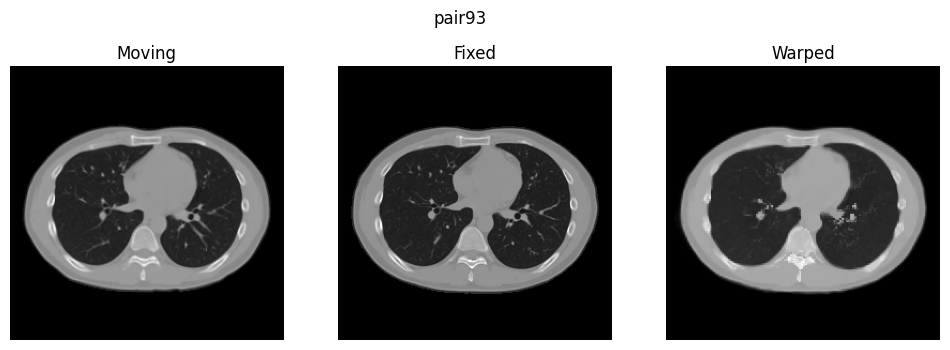

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -3.259629011154175e-09
pair94 | Dice=0.9366 | Jaccard=0.8807 | SSIM=0.9699 | FSIM=nan | RMSE=165.7905 | NCC=0.9895


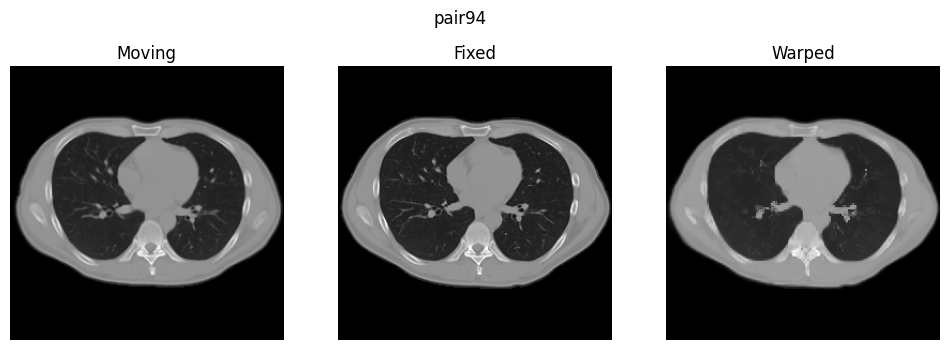

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.3283064365386963e-09
pair95 | Dice=0.9638 | Jaccard=0.9301 | SSIM=0.9712 | FSIM=nan | RMSE=151.6888 | NCC=0.9913


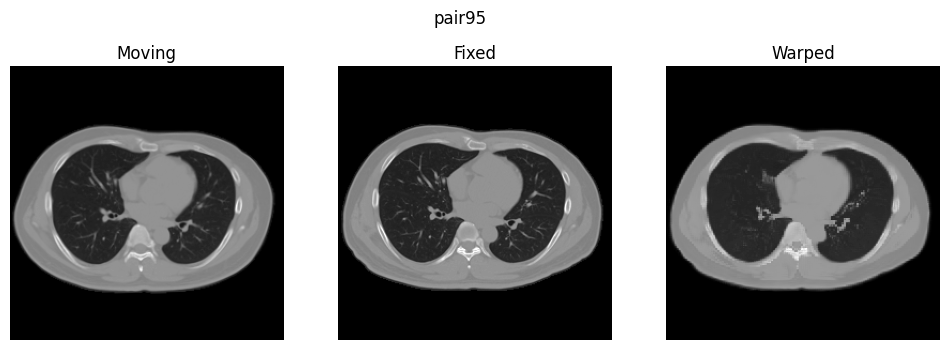

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.0954757928848267e-09
pair96 | Dice=0.9765 | Jaccard=0.9540 | SSIM=0.9720 | FSIM=nan | RMSE=144.0887 | NCC=0.9923


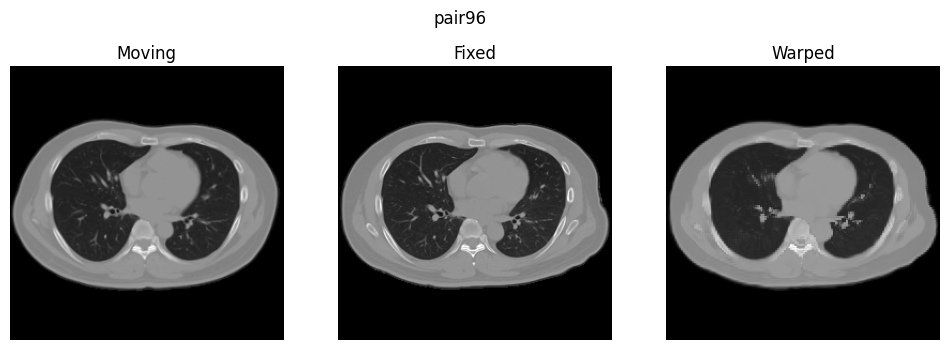

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -2.9249349609017372e-09
pair97 | Dice=0.9790 | Jaccard=0.9589 | SSIM=0.9707 | FSIM=nan | RMSE=140.5651 | NCC=0.9926


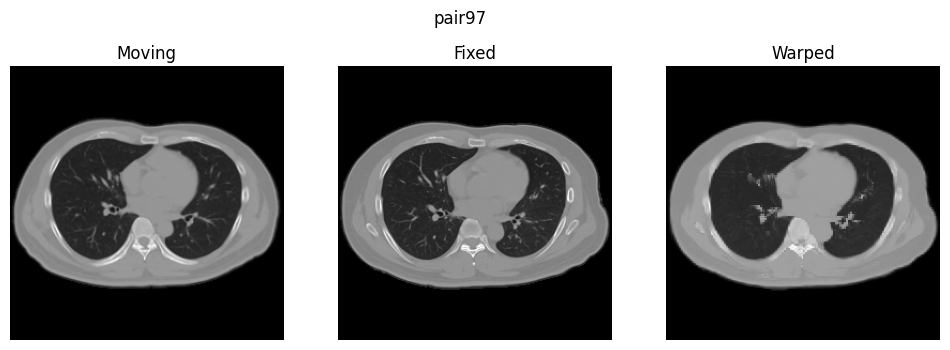

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.587935447692871e-09
pair98 | Dice=0.9500 | Jaccard=0.9048 | SSIM=0.9743 | FSIM=nan | RMSE=142.5034 | NCC=0.9920


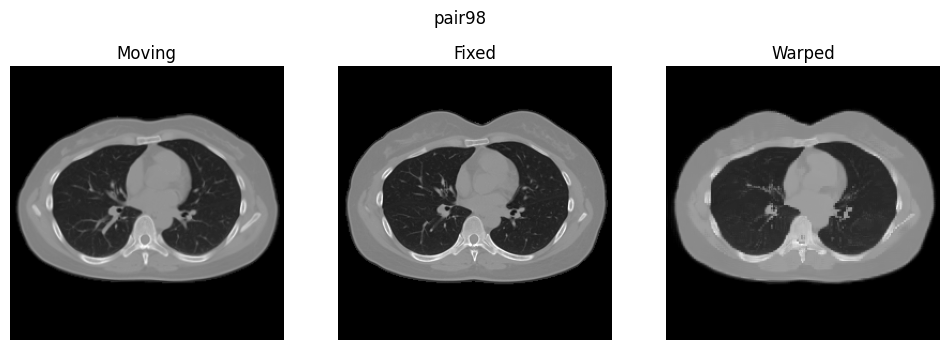

[Warning] FSIM could not be calculated: Expected values to be greater or equal to 0, got -5.587935447692871e-09
pair99 | Dice=0.9487 | Jaccard=0.9025 | SSIM=0.9639 | FSIM=nan | RMSE=153.7954 | NCC=0.9910


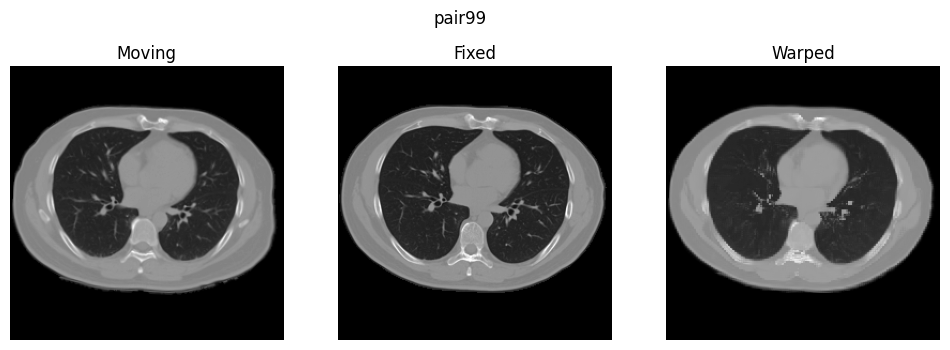

成功した結果数: 101


,pair,Dice,Jaccard,SSIM,FSIM,RMSE,NCC
0,pair1,0.941342,0.889183,0.970894,NaN,165.220184,0.989448
1,pair10,0.950960,0.906505,0.974200,NaN,133.388412,0.992249
2,pair100,0.926320,0.862753,0.970423,NaN,153.662659,0.990234
3,pair101,0.959391,0.921952,0.972050,NaN,145.222046,0.992138
4,pair11,0.940736,0.888104,0.967324,NaN,160.779602,0.989679
...,...,...,...,...,...,...,...
96,pair95,0.963764,0.930062,0.971153,NaN,151.688766,0.991305
97,pair96,0.976468,0.954017,0.971978,NaN,144.088699,0.992301
98,pair97,0.979038,0.958937,0.970680,NaN,140.565109,0.992646
99,pair98,0.950030,0.904817,0.974328,NaN,142.503403,0.992045


             Dice     Jaccard        SSIM  FSIM        RMSE         NCC
count  101.000000  101.000000  101.000000   0.0  101.000000  101.000000
mean     0.958032    0.920030    0.963217   NaN  187.258823    0.983619
std      0.018290    0.033637    0.018356   NaN   91.200270    0.022615
min      0.911378    0.837184    0.870191   NaN  132.177063    0.856518
25%      0.944509    0.894852    0.962915   NaN  147.338455    0.988074
50%      0.958296    0.919930    0.968074   NaN  160.617218    0.990028
75%      0.973034    0.947483    0.972638   NaN  178.881424    0.991250
max      0.992213    0.984545    0.979723   NaN  641.464844    0.992646


: 

In [ ]:
import os, glob
import pandas as pd

parent_folder = r"D:\Yamato\Registered_output_NPZ"
pair_folders = sorted(glob.glob(os.path.join(parent_folder, "pair*")))

print("見つかったペア数:", len(pair_folders))

all_results = []

for pf in pair_folders:
    process_pair(
        pf,
        model,
        transformer,
        device,
        all_results,
        slice_z=64,
        visualize=True
    )

df = pd.DataFrame(all_results)

print("成功した結果数:", len(all_results))
display(df)
print(df.describe())

In [ ]:
all_results = []

pair_paths = sorted(glob.glob(os.path.join(pair_folder, "*")))

for pf in pair_paths:
    process_pair(
        pf,
        model,
        transformer,
        device,
        all_results,
        slice_z=64,
        visualize=True
    )

print("保存された結果数:", len(all_results))

保存された結果数: 0


In [ ]:
import os, glob

print("親フォルダ:", pair_folder)
print("親フォルダ存在:", os.path.exists(pair_folder))

pair_paths = sorted(glob.glob(os.path.join(pair_folder, "*")))
print("見つかった中身の数:", len(pair_paths))
print(pair_paths[:10])

for pf in pair_paths[:5]:
    print("----")
    print("pf:", pf)
    print("isdir:", os.path.isdir(pf))
    print("npz数:", len(glob.glob(os.path.join(pf, "*.npz"))))
    print(glob.glob(os.path.join(pf, "*.npz")))

親フォルダ: D:\Registered_output_NPZ\pair101
親フォルダ存在: False
見つかった中身の数: 0
[]


In [ ]:
import os, glob

print(os.path.exists(r"D:\Registered_output_NPZ"))
print(glob.glob(r"D:\Registered_output_NPZ\*")[:20])

False
[]


In [ ]:
import glob

print(glob.glob(r"D:\*Registered*"))
print(glob.glob(r"D:\*NPZ*"))

[]
[]


In [ ]:
import glob, os

pair_folder = r"D:\Yamato\Registered_output_NPZ\pair101"

print(os.path.exists(pair_folder))
print(glob.glob(os.path.join(pair_folder, "*.npz")))

True
['D:\\Yamato\\Registered_output_NPZ\\pair101\\fixed_masked_B_MIC53945_2020_0515.npz', 'D:\\Yamato\\Registered_output_NPZ\\pair101\\registered_masked_A_MIC53945_2019_0604.npz']


pair101 | RMSE=151.2181 | MS-SSIM=0.9671 | Dice=0.9605


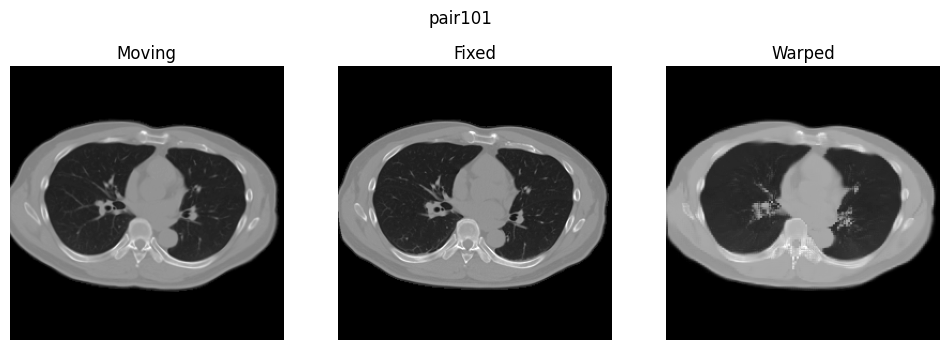

保存された結果数: 1
[{'pair': 'pair101', 'RMSE': 151.2180938720703, 'MS_SSIM': 0.9670905470848083, 'Dice': 0.9604585766792297}]


In [ ]:
all_results = []

process_pair(
    pair_folder,
    model,
    transformer,
    device,
    all_results,
    slice_z=64,
    visualize=True
)

print("保存された結果数:", len(all_results))
print(all_results)

In [ ]:
import numpy as np

train_path = r'D:\Saito\Data\TrainData_NoBed.npz'
data = np.load(train_path)

print(data.files)

['Train']


In [ ]:
import numpy as np

path = r'D:\Saito\Data\TestData\pair1\fixed_masked_B_MIC00197_2019_0406.npz'
data = np.load(path)

print(data.files)

['Train']


In [ ]:
key = data.files[0]
x_np = data[key]

print(key)
print(x_np.shape)
print(x_np.dtype)

Train
(128, 256, 256)
float64


In [ ]:
import torch

x = torch.tensor(x_np, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

x_analysis = analysis_filter_3d(x, analysis)
x_down = down_sampling_3d(x_analysis)
x_up = up_sampling_3d(x_down)
x_rec, x_rec_bands = synthesis_filter_3d(x_up, synthesis_filters)

print("mean error:", torch.mean(torch.abs(x - x_rec)).item())
print("max error:", torch.max(torch.abs(x - x_rec)).item())


In [ ]:
from pathlib import Path
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import glob
from skimage.metrics import structural_similarity as ssim
from tabulate import tabulate
from piq import fsim

# ======================
# 定数（ここで評価したいスライス範囲を指定）
# ======================
CT_MIN, CT_MAX = -1200.0, 3146.98
SLICE_SIZE = (64, 128, 128)
SLICE_IDX_VIEW = 32    # デフォルト表示スライス（範囲指定がある場合は中央スライスが使われる）
SLICE_IDX_FSIM = 28

# 評価したいスライス範囲を指定（例: 20〜40）
# None にすると全ボリュームで評価します
SLICE_START = None
SLICE_END = None

# ======================
# 評価関数（変更なし）
# ======================
def compute_rmse(vol1, vol2):
    return np.sqrt(np.mean((vol1 - vol2) ** 2))

import torch
import torch.nn.functional as F
import numpy as np

def _gaussian_kernel_3d(window_size=7, sigma=1.5, device='cpu', dtype=torch.float32):
    coords = torch.arange(window_size, device=device, dtype=dtype) - window_size // 2
    g1 = torch.exp(-(coords**2) / (2 * sigma**2))
    g1 = g1 / g1.sum()
    g3 = g1[:, None, None] * g1[None, :, None] * g1[None, None, :]
    return g3.unsqueeze(0).unsqueeze(0)  # shape (1,1,D,H,W)

def _ssim_components_3d(x, y, window, K1=0.01, K2=0.03, eps=1e-12):
    """
    Compute luminance, contrast, structure maps for 3D volumes.
    x,y : tensors with shape (N,1,D,H,W)
    window : gaussian kernel shape (1,1,d,h,w)
    returns (l_map, cs_map) where cs_map = contrast * structure
    """
    pad = tuple([s//2 for s in window.shape[-3:]])
    mu_x = F.conv3d(x, window, padding=pad)
    mu_y = F.conv3d(y, window, padding=pad)

    mu_x_sq = mu_x * mu_x
    mu_y_sq = mu_y * mu_y
    mu_xy = mu_x * mu_y

    sigma_x_sq = F.conv3d(x * x, window, padding=pad) - mu_x_sq
    sigma_y_sq = F.conv3d(y * y, window, padding=pad) - mu_y_sq
    sigma_xy = F.conv3d(x * y, window, padding=pad) - mu_xy

    sigma_x_sq = torch.clamp(sigma_x_sq, min=0.0)
    sigma_y_sq = torch.clamp(sigma_y_sq, min=0.0)

    sigma_x = torch.sqrt(sigma_x_sq + eps)
    sigma_y = torch.sqrt(sigma_y_sq + eps)

    # Estimate L (data range) per-sample for numeric C's
    N = x.shape[0]
    max_x = x.view(N, -1).max(dim=1)[0].view(N,1,1,1,1)
    min_x = x.view(N, -1).min(dim=1)[0].view(N,1,1,1,1)
    max_y = y.view(N, -1).max(dim=1)[0].view(N,1,1,1,1)
    min_y = y.view(N, -1).min(dim=1)[0].view(N,1,1,1,1)
    L = torch.max(max_x - min_x, max_y - min_y)
    L = torch.clamp(L, min=eps)

    C1 = (K1 * L) ** 2
    C2 = (K2 * L) ** 2
    C3 = C2 / 2.0

    l_map = (2.0 * mu_xy + C1) / (mu_x_sq + mu_y_sq + C1 + eps)
    contrast = (2.0 * sigma_x * sigma_y + C2) / (sigma_x_sq + sigma_y_sq + C2 + eps)
    structure = (sigma_xy + C3) / (sigma_x * sigma_y + C3 + eps)

    cs_map = contrast * structure
    return l_map.clamp(min=eps), cs_map.clamp(min=eps)

def ms_ssim_3d(vol1, vol2,
               window_size=7, sigma=1.5,
               levels=5,
               weights=None,
               K1=0.01, K2=0.03, eps=1e-12,
               device=None):
    """
    Multi-scale SSIM for 3D volumes.
    vol1, vol2 : torch tensor or numpy array, shapes supported:
        (N,C,D,H,W), (C,D,H,W), (D,H,W)
    levels : number of scales (default 5)
    weights : list/tuple of length `levels` of weights summing to 1 (if None, use default MS-SSIM weights)
    returns: python float (mean MS-SSIM over batch)
    """
    # default MS-SSIM weights from the original paper (for 5 scales)
    if weights is None:
        # note: these are standard for 5-scale MS-SSIM
        weights = [0.0448, 0.2856, 0.3001, 0.2363, 0.1333]
    if len(weights) != levels:
        raise ValueError("len(weights) must equal levels")

    # convert numpy -> torch
    is_numpy = isinstance(vol1, np.ndarray) or isinstance(vol2, np.ndarray)
    if is_numpy:
        vol1 = torch.from_numpy(np.array(vol1))
        vol2 = torch.from_numpy(np.array(vol2))

    if not torch.is_tensor(vol1) or not torch.is_tensor(vol2):
        raise TypeError("vol1/vol2 must be numpy or torch tensor")

    # determine device
    if device is None:
        device = vol1.device if hasattr(vol1, 'device') else torch.device('cpu')
    device = torch.device(device)

    vol1 = vol1.to(device=device, dtype=torch.float32)
    vol2 = vol2.to(device=device, dtype=torch.float32)

    # normalize shapes to (N,C,D,H,W)
    def _ensure5d(x):
        if x.dim() == 5:
            return x
        if x.dim() == 4:
            return x.unsqueeze(0)
        if x.dim() == 3:
            return x.unsqueeze(0).unsqueeze(0)
        raise ValueError("Unsupported tensor shape: {}".format(x.shape))

    x = _ensure5d(vol1)
    y = _ensure5d(vol2)

    # unify channels by mean (if needed)
    if x.shape[1] != y.shape[1] or x.shape[1] > 1:
        x = x.mean(dim=1, keepdim=True)
        y = y.mean(dim=1, keepdim=True)

    N, C, D, H, W = x.shape

    # create gaussian kernel once
    window = _gaussian_kernel_3d(window_size=window_size, sigma=sigma, device=device, dtype=x.dtype)

    mcs = []   # mean contrast-structure per scale
    for lvl in range(levels):
        # if volume becomes too small to downsample, stop early
        if min(D, H, W) < 2:
            # compute final scale components and break
            l_map, cs_map = _ssim_components_3d(x, y, window, K1=K1, K2=K2, eps=eps)
            mcs.append(cs_map.view(N, -1).mean(dim=1))  # shape (N,)
            break

        l_map, cs_map = _ssim_components_3d(x, y, window, K1=K1, K2=K2, eps=eps)
        # mean over spatial dims gives per-sample scalar
        mcs.append(cs_map.view(N, -1).mean(dim=1))

        # downsample for next scale using average pooling (anti-aliasing)
        # kernel_size=2, stride=2
        x = F.avg_pool3d(x, kernel_size=2, stride=2, padding=0)
        y = F.avg_pool3d(y, kernel_size=2, stride=2, padding=0)
        N, C, D, H, W = x.shape

    # last scale luminance
    l_map, cs_map = _ssim_components_3d(x, y, window, K1=K1, K2=K2, eps=eps)
    l_mean = l_map.view(N, -1).mean(dim=1)  # per-sample

    # If we generated fewer mcs than requested levels (due to small volume), adjust weights
    actual_levels = len(mcs)
    if actual_levels < levels:
        # use last `actual_levels` weights and normalized
        w = torch.tensor(weights[:actual_levels], device=device, dtype=x.dtype)
        w = w / w.sum()
        used_weights = w
        # last weight for luminance is taken as original last weight mapped proportionally
        lum_weight = weights[min(actual_levels-1, len(weights)-1)]
    else:
        used_weights = torch.tensor(weights[:levels-1], device=device, dtype=x.dtype)  # weights for cs scales except last
        lum_weight = weights[levels-1]

    # compute MS-SSIM per sample:
    # product over scales of (mcs_i ^ weight_i)  and multiply by (l_mean ^ lum_weight)
    # convert list of tensors to shape (actual_levels, N)
    mcs_t = torch.stack(mcs[:actual_levels], dim=0)  # shape (actual_levels, N)
    # choose weights for these mcs: if actual_levels == levels -> first (levels-1) are cs weights, last is cs too
    if actual_levels == levels:
        cs_weights = torch.tensor(weights[:levels-1], device=device, dtype=x.dtype)
        # there are levels-1 cs entries and last is l_mean
        # mcs_t has length levels-1 (we appended cs for each scale before downsample), plus we still have final cs? 
        # Here we've appended cs at each level before downsampling, and computed final l_map after last downsample.
        # For typical MS-SSIM: use cs means from all levels and l only from last one.
        # So mcs_t currently includes cs for all levels (length == levels). In our loop we appended cs each iteration, and after final downsample we appended final cs too.
        # To match standard weights: use weights[:levels] for cs and lum_weight for l.
        cs_weights = torch.tensor(weights[:actual_levels], device=device, dtype=x.dtype)
    else:
        # when smaller, distribute weights proportionally — use used_weights for cs
        cs_weights = used_weights

    # Ensure cs_weights length matches mcs_t length
    if cs_weights.numel() != mcs_t.shape[0]:
        # simple fallback: evenly distribute
        cs_weights = torch.ones(mcs_t.shape[0], device=device, dtype=x.dtype) / float(mcs_t.shape[0])

    # raise mcs to weights and multiply (per-sample)
    # mcs_t ** cs_weights[:,None] -> shape (L, N)
    # product over rows -> (N,)
    ms_prod = torch.prod(mcs_t.pow(cs_weights.view(-1,1)), dim=0)
    ms_l = l_mean.pow(float(lum_weight))
    ms_per_sample = ms_prod * ms_l

    # return mean over batch as python float
    return float(ms_per_sample.mean().item())

def compute_fsim(vol1, vol2, device):
    """中央スライスでFSIMを評価（ただしこのスクリプトでは通常中央は範囲中央値に合わせる）"""
    v1 = vol1
    v2 = vol2
    # v1, v2 expected shape (C, D, H, W) or (D, H, W). Normalize access:
    if np.asarray(v1).ndim == 3:
        D = v1.shape[0]
    else:
        D = np.asarray(v1).shape[1]
    idx = min(SLICE_IDX_FSIM, max(0, D - 1))
    # Build tensors robustly for either shape
    if np.asarray(v1).ndim == 3:
        fixed_tensor = torch.tensor(v1[idx]).unsqueeze(0).unsqueeze(0).float().to(device)
        pred_tensor = torch.tensor(v2[idx]).unsqueeze(0).unsqueeze(0).float().to(device)
    else:
        fixed_tensor = torch.tensor(v1[:, idx, :, :]).unsqueeze(1).float().to(device)
        pred_tensor = torch.tensor(v2[:, idx, :, :]).unsqueeze(1).float().to(device)
        fixed_tensor = fixed_tensor[0].unsqueeze(0)
        pred_tensor = pred_tensor[0].unsqueeze(0)
    try:
        return fsim(pred_tensor, fixed_tensor, data_range=1.0, chromatic=False).item()
    except Exception:
        return float('nan')

def compute_ncc(vol1, vol2):
    v1 = vol1.flatten().astype(np.float32)
    v2 = vol2.flatten().astype(np.float32)
    v1_mean = v1.mean()
    v2_mean = v2.mean()
    numerator = np.sum((v1 - v1_mean) * (v2 - v2_mean))
    denominator = np.sqrt(np.sum((v1 - v1_mean) ** 2) * np.sum((v2 - v2_mean) ** 2) + 1e-8)
    return numerator / denominator

def compute_metrics(fixed, transformed, device, model_name):
    """Dice, Jaccard, SSIM, FSIM, RMSE, NCC をまとめて計算（入力は部分ボリュームでも可）"""
    fixed_bin = (fixed > 0.144).astype(int)
    transformed_bin = (transformed > 0.144).astype(int)

    dice = 2.0 * np.logical_and(fixed_bin, transformed_bin).sum() / (fixed_bin.sum() + transformed_bin.sum() + 1e-8)
    jaccard = np.logical_and(fixed_bin, transformed_bin).sum() / (np.logical_or(fixed_bin, transformed_bin).sum() + 1e-8)
#     ssim_val = compute_ssim_3d(fixed, transformed)
    ssim_val = ms_ssim_3d(fixed, transformed, levels=5, device='cpu')
    fsim_val = compute_fsim(fixed, transformed, device)
    ncc_val = compute_ncc(fixed, transformed)

    # RMSE用にCT値を復元
    pred_denorm = transformed * (CT_MAX - CT_MIN) + CT_MIN
    true_denorm = fixed * (CT_MAX - CT_MIN) + CT_MIN
    rmse_val = compute_rmse(true_denorm, pred_denorm)

    return [model_name, dice, jaccard, ssim_val, fsim_val, rmse_val, ncc_val]

# ================================================================
# Wavelet-model evaluation on the same TestData pairs as 128model_Test.ipynb
# ================================================================
# Run this cell after the training cell. It evaluates in exactly the same resized
# space as 128model_Test.ipynb: (64, 128, 128), slices 0..63 by default.
# Set this file to the checkpoint obtained from the curriculum learning notebook.
PROJECT_ROOT = Path('D:/Saito')
DATA_ROOT = PROJECT_ROOT / 'Data/TestData'
EVALUATION_MODEL_PATH = PROJECT_ROOT / 'finetune_checkpoints_different_patients/finetuned_different_patients_final.pth'
EVAL_SLICE_START = 0
EVAL_SLICE_END = 127

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f'TestData directory was not found: {DATA_ROOT.resolve()}')
if not EVALUATION_MODEL_PATH.is_file():
    raise FileNotFoundError(
        'Curriculum weight file was not found. Set EVALUATION_MODEL_PATH to the .pth file you saved after curriculum learning: '
        f'{EVALUATION_MODEL_PATH.resolve()}'
    )

if EVALUATION_MODEL_PATH.is_file():
    try:
        eval_checkpoint = torch.load(EVALUATION_MODEL_PATH, map_location=device, weights_only=True)
    except TypeError:
        eval_checkpoint = torch.load(EVALUATION_MODEL_PATH, map_location=device)
    eval_state = eval_checkpoint['model_state_dict'] if isinstance(eval_checkpoint, dict) and 'model_state_dict' in eval_checkpoint else eval_checkpoint
    model3D.load_state_dict(eval_state)
    print(f'Loaded evaluation weights: {EVALUATION_MODEL_PATH.resolve()}')
else:
    print('Final checkpoint not found; evaluating the model currently held in memory.')

SHOW_WAVELET_STEPS = True

def show_wavelet_bands(tensor, title):
    """Show the centre slice of each of the eight Haar-wavelet bands in grayscale."""
    values = tensor[0].detach().float().cpu().numpy()  # (8, D, H, W)
    slice_index = values.shape[1] // 2
    band_images = values[:, slice_index]
    fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
    for index, axis in enumerate(axes.flat):
        image = band_images[index]
        vmin, vmax = np.percentile(image, [1, 99])
        if vmax <= vmin:
            vmax = vmin + 1e-8
        axis.imshow(image, cmap='gray', vmin=vmin, vmax=vmax)
        axis.set_title(f'{analysis_names[index]} / slice {slice_index}')
        axis.axis('off')
    fig.suptitle(f'{title}: shape={tuple(tensor.shape)}')
    plt.show()


def to_n_dhw(array, label):
    """Convert an evaluation archive volume to (N, 128, 256, 256)."""
    array = np.asarray(array, dtype=np.float32)
    if array.ndim == 3:
        array = array[np.newaxis, ...]
    if array.ndim != 4:
        raise ValueError(f'{label}: expected 3-D/4-D data, got {array.shape}')
    if array.shape[1:] == (128, 256, 256):
        return array
    if array.shape[:3] == (128, 256, 256):
        return np.transpose(array, (3, 0, 1, 2))
    if array.shape[1:] == (256, 256, 128):
        return np.transpose(array, (0, 3, 1, 2))
    if array.shape[:3] == (256, 256, 128):
        return np.transpose(array, (3, 2, 0, 1))
    raise ValueError(f'{label}: unsupported shape {array.shape}')



def wavelet_register_fullres(moving_full, fixed_full):
    """Register a pair and retain every wavelet-processing step for inspection."""
    moving_analysis = analysis_filter_3d(moving_full, analysis)
    fixed_analysis = analysis_filter_3d(fixed_full, analysis)
    moving_bands = down_sampling_3d(moving_analysis)
    fixed_bands = down_sampling_3d(fixed_analysis)
    flow = model3D(moving_bands, fixed_bands)
    warped_bands = torch.cat(
        [transformer(moving_bands[:, i:i + 1], flow) for i in range(moving_bands.shape[1])], dim=1
    )
    warped_upsampled = up_sampling_3d(warped_bands)
    warped_full, synthesis_filtered_bands = synthesis_filter_3d(warped_upsampled, synthesis_filters)
    stages = {
        'analysis_filter_output': moving_analysis,
        'downsampled_coefficients': moving_bands,
        'dvf_warped_coefficients': warped_bands,
        'upsampled_coefficients': warped_upsampled,
        'synthesis_filter_output_bands': synthesis_filtered_bands,
    }
    return warped_full, flow, stages


def evaluate_wavelet_pair(pair_dir):
    npz_files = sorted(pair_dir.glob('*.npz'))
    if len(npz_files) != 2:
        raise ValueError(f'{pair_dir}: expected exactly 2 npz files, found {len(npz_files)}')

    # Keep the identical fixed/moving ordering used in 128model_Test.ipynb.
    with np.load(npz_files[0], allow_pickle=False) as archive:
        fixed_full_np = to_n_dhw(archive['Train'], str(npz_files[0]))[0]
    with np.load(npz_files[1], allow_pickle=False) as archive:
        moving_full_np = to_n_dhw(archive['Train'], str(npz_files[1]))[0]
    fixed_full = torch.from_numpy(fixed_full_np).unsqueeze(0).unsqueeze(0).to(device)
    moving_full = torch.from_numpy(moving_full_np).unsqueeze(0).unsqueeze(0).to(device)

    model3D.eval()
    with torch.no_grad():
        warped_full, flow, stages = wavelet_register_fullres(moving_full, fixed_full)
        if SHOW_WAVELET_STEPS:
            print('Input CT:', moving_full.shape)
            print('Analysis-filter output:', stages['analysis_filter_output'].shape)
            print('Downsampled coefficients:', stages['downsampled_coefficients'].shape)
            print('DVF-warped coefficients:', stages['dvf_warped_coefficients'].shape)
            print('Upsampled coefficients:', stages['upsampled_coefficients'].shape)
            print('Synthesis-filter output bands:', stages['synthesis_filter_output_bands'].shape)
            show_wavelet_bands(stages['analysis_filter_output'], 'Analysis filter output')
            show_wavelet_bands(stages['downsampled_coefficients'], 'After downsampling')
            show_wavelet_bands(stages['dvf_warped_coefficients'], 'After DVF warp')
            show_wavelet_bands(stages['upsampled_coefficients'], 'After upsampling')
            show_wavelet_bands(
                stages['synthesis_filter_output_bands'],
                'After Synthesis filters (before summing 8 bands)',
            )
        # Evaluate the inverse-wavelet reconstruction at original resolution.
        fixed_eval = fixed_full
        moved_eval = warped_full

    print(flow.shape)
    print(moved_eval.shape)
    fixed_np = fixed_eval[0, 0].cpu().numpy()
    moved_np = moved_eval[0, 0].cpu().numpy()
    s0 = max(0, EVAL_SLICE_START)
    s1 = min(fixed_np.shape[0] - 1, EVAL_SLICE_END)

    moving_np = moving_full[0, 0].cpu().numpy()
    display_slice = s0 + (s1 - s0) // 2
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
    for axis, image, title in zip(
        axes,
        (moving_np[display_slice], fixed_np[display_slice], moved_np[display_slice]),
        ('Moving', 'Fixed', 'Synthesis result (Warped)'),
    ):
        axis.imshow(image, cmap='gray')
        axis.set_title(title)
        axis.axis('off')
    fig.suptitle(f'{pair_dir.name} / slice {display_slice}')
    plt.show()
    result = compute_metrics(
        fixed_np[s0:s1 + 1][np.newaxis, ...],
        moved_np[s0:s1 + 1][np.newaxis, ...],
        device,
        'Curriculum+TestData',
    )
    print(f'\n=== 📂 ペア: {pair_dir.name} の評価結果 (slices {s0}..{s1}) ===')
    print(tabulate(
        [result],
        headers=['モデル名', 'Dice', 'Jaccard', 'SSIM', 'FSIM', 'RMSE', 'NCC'],
        floatfmt='.4f', tablefmt='github',
    ))
    return result


all_results = []
for pair_dir in sorted(path for path in DATA_ROOT.iterdir() if path.is_dir()):
    all_results.append(evaluate_wavelet_pair(pair_dir))

if all_results:
    values = np.asarray([row[1:] for row in all_results], dtype=np.float64)
    print('\n=== 📊 全ペアの平均結果 ===')
    print(tabulate(
        [['Curriculum+TestData', *values.mean(axis=0)]],
        headers=['モデル名', '平均Dice', '平均Jaccard', '平均SSIM', '平均FSIM', '平均RMSE', '平均NCC'],
        floatfmt='.4f', tablefmt='github',
    ))
